# Sampling-Based Quadrotor Trajectory Planning in Pure JAX

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arunkumar-singh/drone_course_repo/blob/main/tutorials/quadrotor_sampling_planner_jax_colab.ipynb)

Welcome to this standalone, interactive tutorial on **Sampling-Based Receding-Horizon Motion Planning** for quadrotors in **pure JAX** (based on *Sampling Polynomial Trajectories* — Mueller, Hehn & D'Andrea 2015; Mellinger & Kumar 2011; Richter et al. 2013).

At every planning cycle ($T = 2.0\,\text{s}$ horizon, $\Delta = 0.25\,\text{s}$ execution prefix), the drone samples candidate terminal motion states around the goal direction, solves **closed-form degree-7 minimum-snap polynomials** in normalized time $u = t/T$, checks whole-primitive obstacle clearance and kinematic limits, scores surviving primitives, and hands off position, velocity, acceleration, and jerk seamlessly to the next replanning cycle.

---

### Progressive 3-Part Architecture

1. **Part 1 — Minimum-Snap Motion Primitives**
   - **Block 1A (Beginner Block)**: Closed-form normalized-time solver (`compute_min_snap_coeffs`), derivative evaluator (`eval_primitive`), and exact shifted-Legendre snap integral (`compute_snap_cost` / `Q4_MATRIX`) verified on 1D rest-to-rest duration sweeps and 2D moving-endpoint curves.
   - **Block 1B (`jax.vmap` Fan Sampling)**: Vectorized 2D and 3D candidate generation (`sample_candidates_2d`, `sample_candidates_3d`) producing the 34-candidate trajectory fan around an obstacle.
2. **Part 2 — Trajectory Selector & Cost Block**
   - Whole-primitive collision and speed/acceleration filtering (`eval_batch_pva`, `check_feasibility`), Slide 23 goal + smoothness + duration scoring (`score_and_select`, reusing Part 1's `compute_snap_cost`), TF32-safe GPU numerics (`Precision.HIGHEST`), and deterministic masked `argmin` selection (`select_best_trajectory`).
3. **Part 3 — Final Receding-Horizon Sampling Planner**
   - **Block 3A**: Complete receding-horizon step (`plan_step_2d`, `plan_step_3d`), `jax.lax.cond` braking contingency fallback (`compute_braking_primitive`), closed-loop mission runners (`run_mission_2d`, `run_mission_3d`), and pure-XLA `jax.lax.scan` rollouts (`rollout_fixed_horizon_2d`, `rollout_fixed_horizon_3d`).
   - **Block 3B**: Lecture diagnostics (Slides 25–27 + junction continuity & telemetry) and an inline closed-loop `mediapy` video animation.
   - **Block 3C**: GPU/CPU XLA benchmarks (up to 64 parallel missions via `jax.vmap` $\times$ `jax.lax.scan`) and a 3D multi-obstacle corridor flight ($M = 6$ spheres, 136 candidates/cycle).


In [1]:
# =============================================================================
# Setup: Install only missing packages (preserve Colab's preinstalled CUDA JAX)
# =============================================================================
import importlib.util
import shutil
import subprocess
import sys

_missing = []
try:
    import jax
    import jax.numpy as jnp
except ImportError:
    _missing.append("jax")

for _mod, _pkg in [
    ("numpy", "numpy"),
    ("matplotlib", "matplotlib"),
    ("mediapy", "mediapy"),
    ("imageio_ffmpeg", "imageio-ffmpeg"),
]:
    if importlib.util.find_spec(_mod) is None:
        _missing.append(_pkg)

if _missing:
    print(f"Installing missing packages: {_missing}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

from functools import partial
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch
import mediapy as media
import imageio_ffmpeg

if shutil.which("ffmpeg") is None:
    media.set_ffmpeg(imageio_ffmpeg.get_ffmpeg_exe())

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 11.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "legend.fontsize": 9,
    "lines.linewidth": 2.0,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
})

print(f"JAX version:     {jax.__version__}")
print(f"Default backend: {jax.default_backend()}")
print(f"Devices:         {jax.devices()}")


JAX version:     0.6.2


Default backend: gpu
Devices:         [CudaDevice(id=0)]


---
## Part 1 — Minimum-Snap Motion Primitives

### Why Jerk and Snap Matter for Quadrotors (Slide 4)
Near hover with small pitch angle $\theta$ and thrust near $mg$, horizontal acceleration satisfies:
$$\ddot{x} \approx g\theta, \qquad x^{(3)} \approx g\dot{\theta}, \qquad \tau_\theta \approx I_\theta \ddot{\theta} \approx \frac{I_\theta}{g} x^{(4)}$$
- **Jerk** $j = x^{(3)}$ governs the **rate of tilt change** $\dot{\theta}$.
- **Snap** $x^{(4)}$ governs the **angular acceleration and torque demand** $\tau_\theta$.

Minimizing integrated squared snap $J_4 = \int_0^T \|\mathbf{p}^{(4)}(t)\|^2\,dt$ with fixed endpoint position, velocity, acceleration, and jerk yields a **degree-7 polynomial** per coordinate ($x^{(8)} \equiv 0$, Slide 5 & Slide 33).

### Normalized Time & Closed-Form Boundary Solver (Slides 6, 16–17, 32)
Define normalized time $u = t / T \in [0, 1]$ and $q(u) = x(Tu)$ so physical derivatives scale cleanly as:
$$q'(u) = T v(t), \qquad q''(u) = T^2 a(t), \qquad q^{\prime\prime\prime}(u) = T^3 j(t), \qquad q^{(4)}(u) = T^4 x^{(4)}(t)$$

Decompose $q(u)$ into the **initial-motion cubic** $g(u)$ plus the remaining degree $4\dots 7$ correction:
$$g(u) = x_0 + T v_0 u + \frac{1}{2}T^2 a_0 u^2 + \frac{1}{6}T^3 j_0 u^3, \qquad q(u) = g(u) + b_4 u^4 + b_5 u^5 + b_6 u^6 + b_7 u^7$$

Evaluating the normalized endpoint residuals $\rho_\ell = T^\ell x_f^{(\ell)} - g^{(\ell)}(1)$ for $\ell = 0, 1, 2, 3$:
$$\begin{aligned}
\rho_0 &= x_f - x_0 - Tv_0 - \tfrac{1}{2}T^2 a_0 - \tfrac{1}{6}T^3 j_0, &
\rho_1 &= Tv_f - Tv_0 - T^2 a_0 - \tfrac{1}{2}T^3 j_0, \\
\rho_2 &= T^2 a_f - T^2 a_0 - T^3 j_0, &
\rho_3 &= T^3 j_f - T^3 j_0,
\end{aligned}$$
the constant $4 \times 4$ boundary matrix inverts once in closed form (Slide 32):
$$\begin{aligned}
b_4 &= 35\rho_0 - 15\rho_1 + \tfrac{5}{2}\rho_2 - \tfrac{1}{6}\rho_3, &
b_5 &= -84\rho_0 + 39\rho_1 - 7\rho_2 + \tfrac{1}{2}\rho_3, \\
b_6 &= 70\rho_0 - 34\rho_1 + \tfrac{13}{2}\rho_2 - \tfrac{1}{2}\rho_3, &
b_7 &= -20\rho_0 + 10\rho_1 - 2\rho_2 + \tfrac{1}{6}\rho_3.
\end{aligned}$$

### Exact Smoothness Cost $J_4$ via Shifted-Legendre Modes (Slide 34)
Analytically, $J_4 = T^{-7} \sum_{d=1}^D \mathbf{b}_d^\top Q_4 \mathbf{b}_d$, where $(Q_4)_{k,\ell} = \frac{k!}{(k-4)!}\frac{\ell!}{(\ell-4)!}\frac{1}{k+\ell-7}$ for $k,\ell \ge 4$. Because $Q_4[4:,4:]$ is ill-conditioned in naive `float32` subtraction, we factor $q^{(4)}(u) = \sum_{m=0}^3 c_m P_m(2u-1)$ via `_LEGENDRE_M` so $J_4 = T^{-7} \sum_{d,m} \frac{c_{m,d}^2}{2m+1}$ — **algebraically identical** to $\mathbf{b}^\top Q_4 \mathbf{b}/T^7$, strictly non-negative, and immune to `float32` cancellation or GPU TF32 truncation!


In [2]:
# =============================================================================
# Block 1A: Core Minimum-Snap Functions (Pure JAX, JIT-compiled)
# =============================================================================

# Exact Q4 smoothness cost matrix from Slide 34:
#   (Q4)_{k, l} = [k! / (k - 4)!] * [l! / (l - 4)!] / (k + l - 7) for k, l >= 4.
Q4_MATRIX: jax.Array = jnp.array([
    [0.0, 0.0, 0.0, 0.0,     0.0,     0.0,     0.0,      0.0],
    [0.0, 0.0, 0.0, 0.0,     0.0,     0.0,     0.0,      0.0],
    [0.0, 0.0, 0.0, 0.0,     0.0,     0.0,     0.0,      0.0],
    [0.0, 0.0, 0.0, 0.0,     0.0,     0.0,     0.0,      0.0],
    [0.0, 0.0, 0.0, 0.0,   576.0,  1440.0,  2880.0,   5040.0],
    [0.0, 0.0, 0.0, 0.0,  1440.0,  4800.0, 10800.0,  20160.0],
    [0.0, 0.0, 0.0, 0.0,  2880.0, 10800.0, 25920.0,  50400.0],
    [0.0, 0.0, 0.0, 0.0,  5040.0, 20160.0, 50400.0, 100800.0],
])

# Exact shifted-Legendre factorization M^T W M == Q4[4:, 4:] on u in [0, 1]
_LEGENDRE_M = (
    (24.0, 60.0, 120.0, 210.0),
    (0.0,  60.0, 180.0, 378.0),
    (0.0,   0.0,  60.0, 210.0),
    (0.0,   0.0,   0.0,  42.0),
)
_LEGENDRE_WEIGHTS = (1.0, 1.0 / 3.0, 1.0 / 5.0, 1.0 / 7.0)


def _infer_float_dtype(*args: object) -> jnp.dtype:
    """Infer target floating dtype while preserving JAX weak-type semantics."""
    float_args = []
    for x in args:
        if isinstance(x, float):
            float_args.append(x)
        elif not isinstance(x, int):
            arr = jnp.asarray(x)
            if jnp.issubdtype(arr.dtype, jnp.floating):
                float_args.append(arr)
    if not float_args:
        return jnp.asarray(1.0).dtype
    return jnp.result_type(*float_args)


def _horner_eval(poly_coeffs: jax.Array, u_exp: jax.Array) -> jax.Array:
    """Evaluate sum_k poly_coeffs[k] * u^k via Horner's scheme."""
    val = poly_coeffs[-1]
    for k in range(poly_coeffs.shape[0] - 2, -1, -1):
        val = val * u_exp + poly_coeffs[k]
    return val


@jax.jit
def compute_min_snap_coeffs(
    s0: jax.Array,
    sf: jax.Array,
    T: float,
) -> jax.Array:
    """Compute normalized-time degree-7 minimum-snap polynomial coefficients.

    Args:
        s0: Initial state of shape ``(4, D)`` with rows ``[p0, v0, a0, j0]``.
        sf: Terminal state of shape ``(4, D)`` with rows ``[pf, vf, af, jf]``.
        T: Primitive duration ``T > 0``.

    Returns:
        Monomial coefficients ``coeffs`` of shape ``(8, D)`` for ``u = t / T``.
    """
    dtype = _infer_float_dtype(s0, sf, T)
    s0_arr = jnp.asarray(s0, dtype=dtype)
    sf_arr = jnp.asarray(sf, dtype=dtype)
    if s0_arr.ndim != 2 or s0_arr.shape[0] != 4:
        raise ValueError(f"Expected s0 shape (4, D), got {s0_arr.shape}")
    if sf_arr.shape != s0_arr.shape:
        raise ValueError(f"Expected sf shape {s0_arr.shape}, got {sf_arr.shape}")

    T_arr = jnp.asarray(T, dtype=dtype)
    T2 = T_arr * T_arr
    T3 = T2 * T_arr

    p0, v0, a0, j0 = s0_arr[0], s0_arr[1], s0_arr[2], s0_arr[3]
    pf, vf, af, jf = sf_arr[0], sf_arr[1], sf_arr[2], sf_arr[3]

    # Initial-motion polynomial g(u) = b0 + b1*u + b2*u^2 + b3*u^3
    b0 = p0
    b1 = T_arr * v0
    b2 = 0.5 * T2 * a0
    b3 = (T3 * j0) / 6.0

    # Endpoint residuals rho_l = T^l x_f^(l) - g^(l)(1) (Slide 16)
    rho0 = pf - b0 - b1 - b2 - b3
    rho1 = T_arr * vf - b1 - 2.0 * b2 - 3.0 * b3
    rho2 = T2 * af - 2.0 * b2 - 6.0 * b3
    rho3 = T3 * jf - 6.0 * b3

    # Exact closed-form inverse of Slide 17 boundary matrix (Slide 32)
    b4 = 35.0 * rho0 - 15.0 * rho1 + 2.5 * rho2 - rho3 / 6.0
    b5 = -84.0 * rho0 + 39.0 * rho1 - 7.0 * rho2 + 0.5 * rho3
    b6 = 70.0 * rho0 - 34.0 * rho1 + 6.5 * rho2 - 0.5 * rho3
    b7 = -20.0 * rho0 + 10.0 * rho1 - 2.0 * rho2 + rho3 / 6.0

    return jnp.stack([b0, b1, b2, b3, b4, b5, b6, b7], axis=0)


@jax.jit
def eval_primitive(
    coeffs: jax.Array,
    T: float,
    u: jax.Array | float,
) -> tuple[jax.Array, jax.Array, jax.Array, jax.Array, jax.Array]:
    """Evaluate (pos, vel, acc, jerk, snap) in physical units along u in [0, 1]."""
    dtype = _infer_float_dtype(coeffs, T, u)
    c0 = jnp.asarray(coeffs, dtype=dtype)
    if c0.ndim != 2 or c0.shape[0] != 8:
        raise ValueError(f"Expected coeffs shape (8, D), got {c0.shape}")

    T_arr = jnp.asarray(T, dtype=dtype)
    u_arr = jnp.asarray(u, dtype=dtype)
    u_exp = u_arr[..., None]

    c1 = jnp.arange(1, 8, dtype=dtype)[:, None] * c0[1:]
    c2 = jnp.arange(1, 7, dtype=dtype)[:, None] * c1[1:]
    c3 = jnp.arange(1, 6, dtype=dtype)[:, None] * c2[1:]
    c4 = jnp.arange(1, 5, dtype=dtype)[:, None] * c3[1:]

    pos = _horner_eval(c0, u_exp)
    q1 = _horner_eval(c1, u_exp)
    q2 = _horner_eval(c2, u_exp)
    q3 = _horner_eval(c3, u_exp)
    q4 = _horner_eval(c4, u_exp)

    inv_T = 1.0 / T_arr
    inv_T2 = inv_T * inv_T
    inv_T3 = inv_T2 * inv_T
    inv_T4 = inv_T2 * inv_T2

    return pos, q1 * inv_T, q2 * inv_T2, q3 * inv_T3, q4 * inv_T4


@jax.jit
def compute_snap_cost(coeffs: jax.Array, T: float) -> jax.Array:
    """Compute exact integrated squared snap J_4 via shifted-Legendre modes (Slide 34)."""
    dtype = _infer_float_dtype(coeffs, T)
    c = jnp.asarray(coeffs, dtype=dtype)
    if c.ndim != 2 or c.shape[0] != 8:
        raise ValueError(f"Expected coeffs shape (8, D), got {c.shape}")

    T_arr = jnp.asarray(T, dtype=dtype)
    b4, b5, b6, b7 = c[4], c[5], c[6], c[7]

    # Shifted-Legendre modes c_0..c_3 of q^(4)(u) on [0, 1]
    l0 = 24.0 * b4 + 60.0 * b5 + 120.0 * b6 + 210.0 * b7
    l1 = 60.0 * b5 + 180.0 * b6 + 378.0 * b7
    l2 = 60.0 * b6 + 210.0 * b7
    l3 = 42.0 * b7

    integral_u = jnp.sum(
        l0 * l0 + (l1 * l1) / 3.0 + (l2 * l2) / 5.0 + (l3 * l3) / 7.0
    )
    return integral_u * (T_arr ** -7)


print("Part 1 Block 1A core functions compiled and ready.")


Part 1 Block 1A core functions compiled and ready.


1D Rest-to-Rest Verification (dp = 2.0 m):


  T = 1.5 s | J4(Legendre) = 23598.355 | J4(Q4) = 23598.354 | Exact 100800*dp^2/T^7 = 23598.354 (rel_err=6.61e-08) | max|v|=2.917 m/s, max|a|=6.678 m/s^2
  T = 2.0 s | J4(Legendre) =  3150.000 | J4(Q4) =  3150.000 | Exact 100800*dp^2/T^7 =  3150.000 (rel_err=7.75e-08) | max|v|=2.188 m/s, max|a|=3.757 m/s^2
  T = 3.0 s | J4(Legendre) =   184.362 | J4(Q4) =   184.362 | Exact 100800*dp^2/T^7 =   184.362 (rel_err=6.61e-08) | max|v|=1.458 m/s, max|a|=1.670 m/s^2
Verified normalized coefficients / dp: [0.0, 0.0, 0.0, 0.0, 35.0, -84.0, 70.0, -20.0]


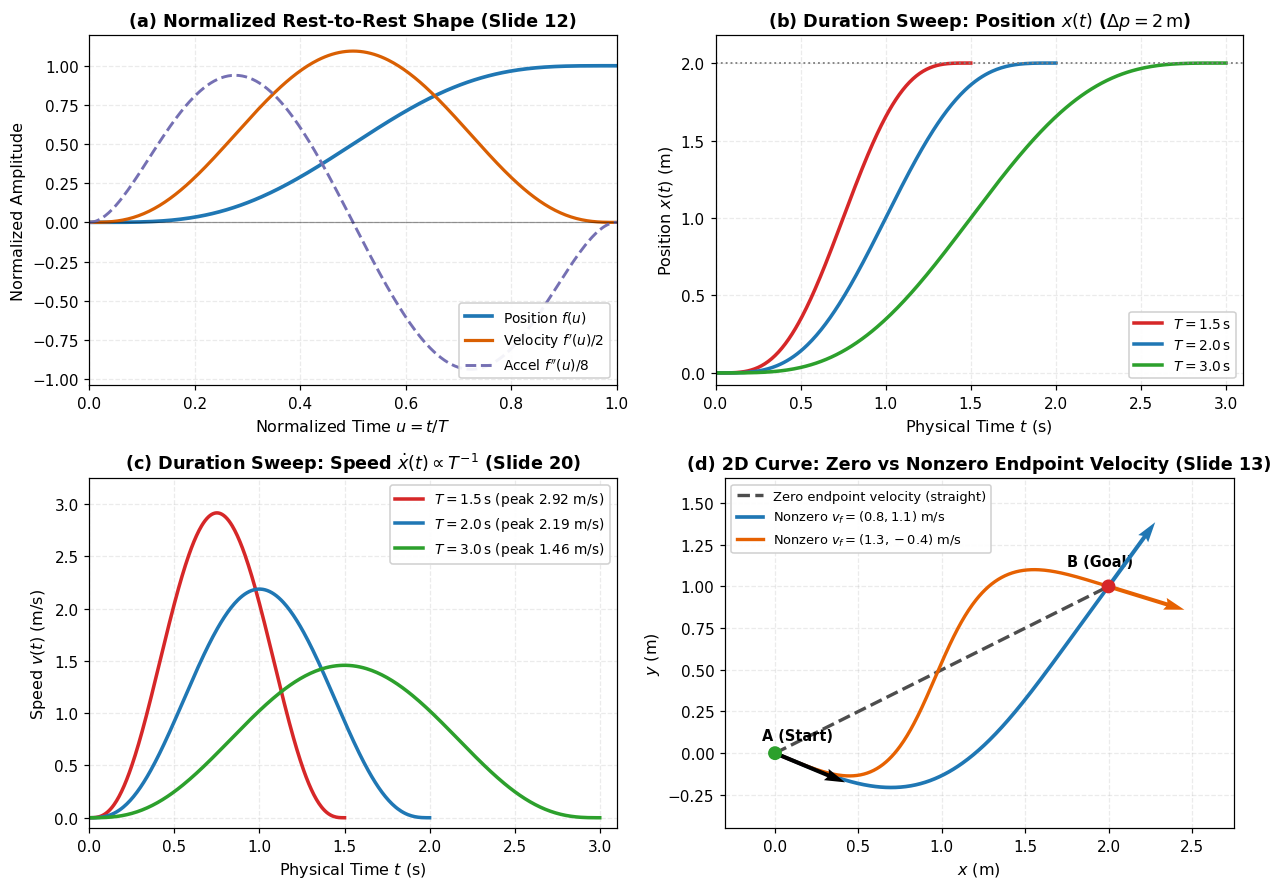

In [3]:
# =============================================================================
# Block 1A Demo: Rest-to-Rest 1D Duration Sweep & 2D Moving-Endpoint Curve
# =============================================================================
dp = 2.0
durations = [1.5, 2.0, 3.0]
s0_1d = jnp.array([[0.0], [0.0], [0.0], [0.0]])
sf_1d = jnp.array([[dp],  [0.0], [0.0], [0.0]])

# Verify Q4_MATRIX == M^T W M on float64 reference
M_np = np.asarray(_LEGENDRE_M, dtype=np.float64)
W_np = np.diag(np.asarray(_LEGENDRE_WEIGHTS, dtype=np.float64))
assert np.allclose(M_np.T @ W_np @ M_np, np.asarray(Q4_MATRIX[4:, 4:], dtype=np.float64))

print("1D Rest-to-Rest Verification (dp = 2.0 m):")
expected_coeffs = np.array([0.0, 0.0, 0.0, 0.0, 35.0, -84.0, 70.0, -20.0]) * dp
u_dense = jnp.linspace(0.0, 1.0, 301)

sweep_data = {}
for T_val in durations:
    c_1d = compute_min_snap_coeffs(s0_1d, sf_1d, T_val)
    c_np = np.asarray(c_1d[:, 0])
    assert np.allclose(c_np, expected_coeffs, atol=1e-5)

    j4_leg = float(compute_snap_cost(c_1d, T_val))
    j4_q4 = float((c_1d[:, 0] @ Q4_MATRIX @ c_1d[:, 0]) / (T_val ** 7))
    j4_exact = 100800.0 * (dp ** 2) / (T_val ** 7)
    rel_err = abs(j4_leg - j4_exact) / j4_exact
    assert rel_err < 1e-6

    pos_1d, vel_1d, acc_1d, _, _ = eval_primitive(c_1d, T_val, u_dense)
    peak_v = float(jnp.max(jnp.abs(vel_1d)))
    peak_a = float(jnp.max(jnp.abs(acc_1d)))
    print(
        f"  T = {T_val:.1f} s | J4(Legendre) = {j4_leg:9.3f} | "
        f"J4(Q4) = {j4_q4:9.3f} | Exact 100800*dp^2/T^7 = {j4_exact:9.3f} "
        f"(rel_err={rel_err:.2e}) | max|v|={peak_v:.3f} m/s, max|a|={peak_a:.3f} m/s^2"
    )
    sweep_data[T_val] = (
        np.asarray(u_dense) * T_val,
        np.asarray(pos_1d[:, 0]),
        np.asarray(vel_1d[:, 0]),
    )

print(f"Verified normalized coefficients / dp: {np.round(c_np / dp, 3).tolist()}")

# 2D Moving-Endpoint Comparison (Slide 13): A=(0,0) -> B=(2,1) in T=2.0 s
A = jnp.array([0.0, 0.0])
B = jnp.array([2.0, 1.0])
T_2d = 2.0

s0_zero = jnp.array([A, [0.0, 0.0], [0.0, 0.0], [0.0, 0.0]])
sf_zero = jnp.array([B, [0.0, 0.0], [0.0, 0.0], [0.0, 0.0]])

v0_mov = jnp.array([1.2, -0.5])
vf_mov1 = jnp.array([0.8, 1.1])
vf_mov2 = jnp.array([1.3, -0.4])

s0_mov = jnp.array([A, v0_mov, [0.0, 0.0], [0.0, 0.0]])
sf_mov1 = jnp.array([B, vf_mov1, [0.0, 0.0], [0.0, 0.0]])
sf_mov2 = jnp.array([B, vf_mov2, [0.0, 0.0], [0.0, 0.0]])

pos_z, _, _, _, _ = eval_primitive(compute_min_snap_coeffs(s0_zero, sf_zero, T_2d), T_2d, u_dense)
pos_m1, _, _, _, _ = eval_primitive(compute_min_snap_coeffs(s0_mov, sf_mov1, T_2d), T_2d, u_dense)
pos_m2, _, _, _, _ = eval_primitive(compute_min_snap_coeffs(s0_mov, sf_mov2, T_2d), T_2d, u_dense)

# Normalized shape curves for Panel (a)
u_np = np.asarray(u_dense)
f_u = 35.0 * u_np**4 - 84.0 * u_np**5 + 70.0 * u_np**6 - 20.0 * u_np**7
fp_u = 140.0 * (u_np**3) * ((1.0 - u_np) ** 3)
fpp_u = 420.0 * (u_np**2) * ((1.0 - u_np) ** 2) * (1.0 - 2.0 * u_np)

# Plot crisp 4-panel Matplotlib figure
fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.2))

# Panel (a): Normalized Shape
ax = axes[0, 0]
ax.plot(u_np, f_u, color="#1f77b4", lw=2.4, label=r"Position $f(u)$")
ax.plot(u_np, fp_u / 2.0, color="#d95f02", lw=2.1, label=r"Velocity $f'(u) / 2$")
ax.plot(u_np, fpp_u / 8.0, color="#7570b3", lw=1.9, ls="--", label=r"Accel $f''(u) / 8$")
ax.axhline(0.0, color="k", lw=0.8, alpha=0.4)
ax.set_title("(a) Normalized Rest-to-Rest Shape (Slide 12)")
ax.set_xlabel("Normalized Time $u = t / T$")
ax.set_ylabel("Normalized Amplitude")
ax.set_xlim(0.0, 1.0)
ax.legend(loc="lower right", framealpha=0.92)

# Panel (b): Duration Sweep — Position
ax = axes[0, 1]
colors_T = ["#d62728", "#1f77b4", "#2ca02c"]
for T_val, col in zip(durations, colors_T):
    t_arr, p_arr, _ = sweep_data[T_val]
    ax.plot(t_arr, p_arr, color=col, lw=2.3, label=f"$T = {T_val:.1f}\\,\\mathrm{{s}}$")
ax.axhline(dp, color="gray", ls=":", lw=1.2)
ax.set_title("(b) Duration Sweep: Position $x(t)$ ($\\Delta p = 2\\,\\mathrm{m}$)")
ax.set_xlabel("Physical Time $t$ (s)")
ax.set_ylabel("Position $x(t)$ (m)")
ax.set_xlim(0.0, 3.1)
ax.set_ylim(-0.08, 2.18)
ax.legend(loc="lower right", framealpha=0.92)

# Panel (c): Duration Sweep — Speed (T^-1 scaling)
ax = axes[1, 0]
for T_val, col in zip(durations, colors_T):
    t_arr, _, v_arr = sweep_data[T_val]
    ax.plot(t_arr, v_arr, color=col, lw=2.3, label=f"$T = {T_val:.1f}\\,\\mathrm{{s}}$ (peak {np.max(v_arr):.2f} m/s)")
ax.set_title(r"(c) Duration Sweep: Speed $\dot{x}(t) \propto T^{-1}$ (Slide 20)")
ax.set_xlabel("Physical Time $t$ (s)")
ax.set_ylabel("Speed $v(t)$ (m/s)")
ax.set_xlim(0.0, 3.1)
ax.set_ylim(-0.1, 3.25)
ax.legend(loc="upper right", framealpha=0.92)

# Panel (d): 2D Zero vs Nonzero Terminal Velocity (Slide 13)
ax = axes[1, 1]
p_z = np.asarray(pos_z)
p_m1 = np.asarray(pos_m1)
p_m2 = np.asarray(pos_m2)
ax.plot(p_z[:, 0], p_z[:, 1], color="#4d4d4d", ls="--", lw=2.2, label="Zero endpoint velocity (straight)")
ax.plot(p_m1[:, 0], p_m1[:, 1], color="#1f77b4", lw=2.4, label="Nonzero $v_f = (0.8, 1.1)$ m/s")
ax.plot(p_m2[:, 0], p_m2[:, 1], color="#e66101", lw=2.2, label="Nonzero $v_f = (1.3, -0.4)$ m/s")

# Draw endpoint velocity vectors
scale = 0.35
ax.quiver(0.0, 0.0, float(v0_mov[0])*scale, float(v0_mov[1])*scale, angles="xy", scale_units="xy", scale=1, color="black", width=0.008, zorder=5)
ax.quiver(2.0, 1.0, float(vf_mov1[0])*scale, float(vf_mov1[1])*scale, angles="xy", scale_units="xy", scale=1, color="#1f77b4", width=0.008, zorder=5)
ax.quiver(2.0, 1.0, float(vf_mov2[0])*scale, float(vf_mov2[1])*scale, angles="xy", scale_units="xy", scale=1, color="#e66101", width=0.008, zorder=5)
ax.scatter([0.0, 2.0], [0.0, 1.0], c=["#2ca02c", "#d62728"], s=65, zorder=6)
ax.text(-0.08, 0.08, "A (Start)", fontsize=9.5, fontweight="bold")
ax.text(1.75, 1.12, "B (Goal)", fontsize=9.5, fontweight="bold")
ax.set_title("(d) 2D Curve: Zero vs Nonzero Endpoint Velocity (Slide 13)")
ax.set_xlabel("$x$ (m)")
ax.set_ylabel("$y$ (m)")
ax.set_xlim(-0.3, 2.75)
ax.set_ylim(-0.45, 1.65)
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper left", fontsize=8.5, framealpha=0.92)

plt.tight_layout()
plt.show()


### Block 1B — Vectorized Candidate Fan Sampling with `jax.vmap` (Slides 1 & 19)

Rather than solving primitives sequentially in a Python loop, we batch all $K$ terminal endpoints and solve them simultaneously in one fused `jax.vmap(compute_min_snap_coeffs, in_axes=(None, 0, None))` call:
- **2D Sampling Grid (`sample_candidates_2d`)**: Fix horizon $T = 2.0\,\text{s}$ and sample polar offsets around the goal bearing $\theta_{\text{goal}}$:
  $$\phi_k = \theta_{\text{goal}} + \Delta\theta_k, \qquad \mathbf{p}_f^{(k)} = \mathbf{p}_0 + \ell_k \begin{bmatrix}\cos\phi_k \\ \sin\phi_k\end{bmatrix}, \qquad \mathbf{v}_f^{(k)} = v_{\text{term}} \begin{bmatrix}\cos\phi_k \\ \sin\phi_k\end{bmatrix}$$
  with $\mathbf{a}_f^{(k)} = \mathbf{j}_f^{(k)} = \mathbf{0}$. Using **11 angles** in $[-75^\circ, +75^\circ]$ and **3 distances** $\{1.5, 2.0, 2.5\}\,\text{m}$, plus **1 stationary goal candidate** ($\mathbf{p}_f = \mathbf{p}_{\text{goal}}, \mathbf{v}_f = \mathbf{a}_f = \mathbf{j}_f = \mathbf{0}$), yields **$K = 34$ candidates**.
- **3D Sampling Grid (`sample_candidates_3d`)**: Extends the same shared `_solve_moving_and_goal_batch` kernel to spherical offsets `(az_angles_deg, el_angles_deg, distances)` around the 3D goal bearing.


Generated candidate fan: coeffs_batch=(34, 8, 2), T_batch=(34,)


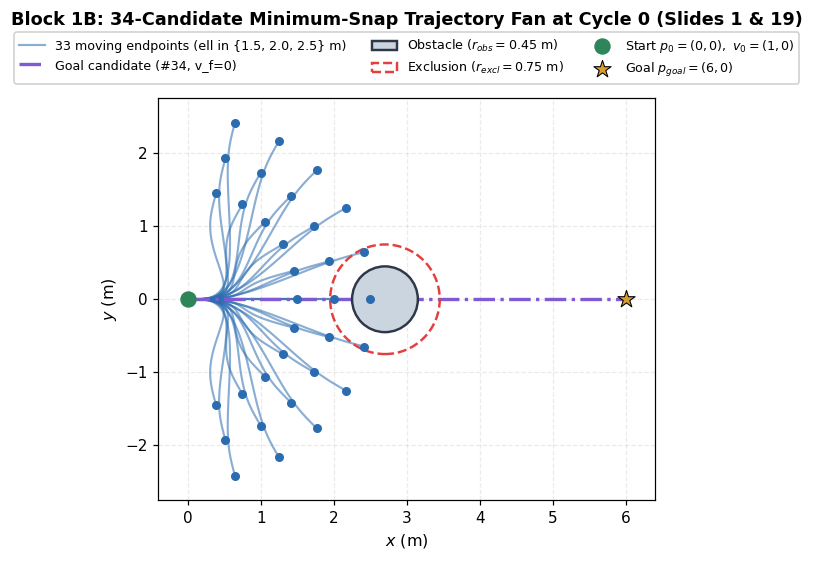

In [4]:
# =============================================================================
# Block 1B: Vectorized 2D & 3D Candidate Fan Sampling (jax.vmap)
# =============================================================================

def _solve_moving_and_goal_batch(
    s0: jax.Array,
    p_goal: jax.Array,
    dist_flat: jax.Array,
    unit_dirs: jax.Array,
    T_arr: jax.Array,
    terminal_speed: float,
    dtype: jnp.dtype,
) -> tuple[jax.Array, jax.Array]:
    """Build moving endpoint states plus stationary goal candidate and vmap-solve."""
    p0 = s0[0]
    speed = jnp.asarray(terminal_speed, dtype=dtype)
    pf_moving = p0[None, :] + dist_flat[:, None] * unit_dirs
    vf_moving = speed * unit_dirs
    zeros = jnp.zeros_like(pf_moving)
    sf_moving = jnp.stack([pf_moving, vf_moving, zeros, zeros], axis=1)

    dim = s0.shape[1]
    sf_goal = jnp.zeros((1, 4, dim), dtype=dtype).at[0, 0].set(p_goal)
    sf_batch = jnp.concatenate([sf_moving, sf_goal], axis=0)

    coeffs_batch = jax.vmap(compute_min_snap_coeffs, in_axes=(None, 0, None))(
        s0, sf_batch, T_arr
    )
    T_batch = jnp.full((sf_batch.shape[0],), T_arr, dtype=dtype)
    return coeffs_batch, T_batch


@jax.jit
def sample_candidates_2d(
    s0: jax.Array,
    p_goal: jax.Array,
    angles_deg: jax.Array,
    distances: jax.Array,
    T: float,
    terminal_speed: float = 1.0,
) -> tuple[jax.Array, jax.Array]:
    """Sample 2D moving endpoints (distances x angles) + 1 stationary goal candidate."""
    dtype = _infer_float_dtype(s0, p_goal, angles_deg, distances, T, terminal_speed)
    s0_arr = jnp.asarray(s0, dtype=dtype)
    goal_arr = jnp.asarray(p_goal, dtype=dtype)
    ang_arr = jnp.asarray(angles_deg, dtype=dtype)
    dist_arr = jnp.asarray(distances, dtype=dtype)
    T_arr = jnp.asarray(T, dtype=dtype)

    if s0_arr.shape != (4, 2):
        raise ValueError(f"Expected s0 shape (4, 2), got {s0_arr.shape}")
    if goal_arr.shape != (2,):
        raise ValueError(f"Expected p_goal shape (2,), got {goal_arr.shape}")

    diff = goal_arr - s0_arr[0]
    theta_goal = jnp.arctan2(diff[1], diff[0])

    dist_grid, ang_grid = jnp.meshgrid(dist_arr, ang_arr, indexing="ij")
    phi = theta_goal + jnp.deg2rad(ang_grid.reshape(-1))
    unit_dirs = jnp.stack([jnp.cos(phi), jnp.sin(phi)], axis=-1)

    return _solve_moving_and_goal_batch(
        s0_arr, goal_arr, dist_grid.reshape(-1), unit_dirs, T_arr, terminal_speed, dtype
    )


@jax.jit
def sample_candidates_3d(
    s0: jax.Array,
    p_goal: jax.Array,
    az_angles_deg: jax.Array,
    el_angles_deg: jax.Array,
    distances: jax.Array,
    T: float,
    terminal_speed: float = 1.0,
) -> tuple[jax.Array, jax.Array]:
    """Sample 3D moving endpoints (distances x el x az) + 1 stationary goal candidate."""
    dtype = _infer_float_dtype(
        s0, p_goal, az_angles_deg, el_angles_deg, distances, T, terminal_speed
    )
    s0_arr = jnp.asarray(s0, dtype=dtype)
    goal_arr = jnp.asarray(p_goal, dtype=dtype)
    az_arr = jnp.asarray(az_angles_deg, dtype=dtype)
    el_arr = jnp.asarray(el_angles_deg, dtype=dtype)
    dist_arr = jnp.asarray(distances, dtype=dtype)
    T_arr = jnp.asarray(T, dtype=dtype)

    if s0_arr.shape != (4, 3):
        raise ValueError(f"Expected s0 shape (4, 3), got {s0_arr.shape}")
    if goal_arr.shape != (3,):
        raise ValueError(f"Expected p_goal shape (3,), got {goal_arr.shape}")

    diff = goal_arr - s0_arr[0]
    az_goal = jnp.arctan2(diff[1], diff[0])
    el_goal = jnp.arctan2(diff[2], jnp.hypot(diff[0], diff[1]))

    dist_grid, el_grid, az_grid = jnp.meshgrid(
        dist_arr, el_arr, az_arr, indexing="ij"
    )
    az = az_goal + jnp.deg2rad(az_grid.reshape(-1))
    el = el_goal + jnp.deg2rad(el_grid.reshape(-1))
    cos_el = jnp.cos(el)
    unit_dirs = jnp.stack(
        [cos_el * jnp.cos(az), cos_el * jnp.sin(az), jnp.sin(el)], axis=-1
    )

    return _solve_moving_and_goal_batch(
        s0_arr, goal_arr, dist_grid.reshape(-1), unit_dirs, T_arr, terminal_speed, dtype
    )


# Generate Cycle 0 34-candidate fan (Slides 1 & 19)
s0_lecture = jnp.array([[0.0, 0.0], [1.0, 0.0], [0.0, 0.0], [0.0, 0.0]])
p_goal_lecture = jnp.array([6.0, 0.0])
angles_lecture = jnp.linspace(-75.0, 75.0, 11)
distances_lecture = jnp.array([1.5, 2.0, 2.5])
T_horizon = 2.0

r_obs, r_drone, delta_safe = 0.45, 0.15, 0.15
obs_center_lecture = jnp.array([[2.70, 0.0]])
obs_excl_lecture = jnp.array([r_obs + r_drone + delta_safe])  # 0.75 m
obs_contact_lecture = jnp.array([r_obs + r_drone])            # 0.60 m

coeffs_c0, T_c0 = sample_candidates_2d(
    s0_lecture, p_goal_lecture, angles_lecture, distances_lecture, T_horizon, terminal_speed=1.0
)
print(f"Generated candidate fan: coeffs_batch={coeffs_c0.shape}, T_batch={T_c0.shape}")

# Evaluate and plot all 34 curves around the obstacle
u_plot = jnp.linspace(0.0, 1.0, 121)
pos_fan, _, _, _, _ = jax.vmap(eval_primitive, in_axes=(0, 0, None))(coeffs_c0, T_c0, u_plot)
pos_fan_np = np.asarray(pos_fan)

fig, ax = plt.subplots(figsize=(9.5, 5.2))
for k in range(33):
    lbl = "33 moving endpoints (ell in {1.5, 2.0, 2.5} m)" if k == 0 else None
    ax.plot(pos_fan_np[k, :, 0], pos_fan_np[k, :, 1], color="#2b6cb0", alpha=0.55, lw=1.4, label=lbl)
ax.scatter(
    pos_fan_np[:33, -1, 0], pos_fan_np[:33, -1, 1],
    color="#2b6cb0", s=24, zorder=4
)
ax.plot(
    pos_fan_np[33, :, 0], pos_fan_np[33, :, 1],
    color="#805ad5", lw=2.2, ls="-.", label="Goal candidate (#34, v_f=0)"
)

# Obstacle body + safety exclusion radius
c_obs = np.asarray(obs_center_lecture[0])
ax.add_patch(Circle(c_obs, r_obs, facecolor="#cbd5e0", edgecolor="#2d3748", lw=1.6, zorder=2, label=f"Obstacle ($r_{{obs}}={r_obs:.2f}$ m)"))
ax.add_patch(Circle(c_obs, float(obs_excl_lecture[0]), facecolor="none", edgecolor="#e53e3e", lw=1.6, ls="--", zorder=3, label=f"Exclusion ($r_{{excl}}={float(obs_excl_lecture[0]):.2f}$ m)"))

ax.scatter([0.0], [0.0], color="#2f855a", s=95, marker="o", zorder=6, label="Start $p_0=(0,0),\\ v_0=(1,0)$")
ax.scatter([6.0], [0.0], color="#d69e2e", s=140, marker="*", edgecolors="k", lw=0.7, zorder=7, label="Goal $p_{goal}=(6,0)$")

ax.set_title("Block 1B: 34-Candidate Minimum-Snap Trajectory Fan at Cycle 0 (Slides 1 & 19)", pad=48)
ax.set_xlabel("$x$ (m)")
ax.set_ylabel("$y$ (m)")
ax.set_xlim(-0.4, 6.4)
ax.set_ylim(-2.75, 2.75)
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3, fontsize=8.3, framealpha=0.95)
plt.tight_layout()
plt.show()


---
## Part 2 — Trajectory Selector & Cost Block

### 1. Whole-Primitive Feasibility Checks (Slide 21)
Checking only the sampled endpoint $\mathbf{p}_k(T_k)$ is **not** enough—a curve can clip an obstacle or exceed motor limits mid-flight. We evaluate every candidate across a dense uniform time grid $u_n \in [0, 1]$ (`n_eval = 201`) and enforce:
- **Obstacle Clearance**:
  $$\|\mathbf{p}_k(t_n) - \mathbf{c}_m\|_2 \ge r_{\text{obs},m} + r_{\text{drone}} + \delta \qquad \forall n, \, \forall m \in \{1,\dots,M\}$$
  For the lecture example, $r_{\text{excl}} = 0.45 + 0.15 + 0.15 = 0.75\,\text{m}$.
- **Kinematic Limits**:
  $$\|\dot{\mathbf{p}}_k(t_n)\|_2 \le v_{\max} = 3.0\,\text{m/s}, \qquad \|\ddot{\mathbf{p}}_k(t_n)\|_2 \le a_{\max} = 5.0\,\text{m/s}^2$$

### 2. Planning Score & Deterministic Selection (Slides 23–24)
Among **only feasible candidates**, we minimize the outer planning score:
$$C_k = w_g \|\mathbf{p}_k(T_k) - \mathbf{p}_{\text{goal}}\|^2 + w_s J_4[\mathbf{p}_k] + w_T T_k$$
with lecture demonstration weights $w_g = 1.0\,\text{m}^{-2}$, $w_s = 10^{-3}\,\text{s}^7/\text{m}^2$ ($\frac{J_4}{1000}$), and $w_T = 0$. Infeasible candidates are masked to $+\infty$ prior to `jnp.argmin`, giving deterministic lowest-index tie-breaking (e.g., `#26` over tied `#30`) with zero Python branching.

### 3. GPU Numerics Note (TF32 Protection)
On NVIDIA Ampere/Ada/Hopper GPUs, JAX matrix contractions (`jnp.einsum`) default to TensorFloat-32 (10-bit mantissa), which introduces $\sim 10^{-2}\,\text{m}$ drift on alternating-sign degree-7 monomials. Setting `precision=jax.lax.Precision.HIGHEST` in `eval_batch_pva` restores full IEEE-754 `float32` accuracy, while `score_and_select` directly reuses Part 1's shifted-Legendre `compute_snap_cost` via `jax.vmap`.


In [5]:
# =============================================================================
# Block 2: Vectorized Evaluator, Feasibility Checker & Trajectory Selector
# =============================================================================

def _poly_basis_matrices(n_eval: int, dtype: jnp.dtype) -> tuple[jax.Array, jax.Array, jax.Array]:
    """Build (n_eval, 8) normalized basis matrices for q(u), q'(u), and q''(u)."""
    u = jnp.linspace(0.0, 1.0, n_eval, dtype=dtype)
    zeros = jnp.zeros_like(u)
    ones = jnp.ones_like(u)

    pows = [ones]
    for _ in range(1, 8):
        pows.append(pows[-1] * u)

    b_pos = jnp.stack(pows, axis=1)
    b_vel = jnp.stack([zeros] + [k * pows[k - 1] for k in range(1, 8)], axis=1)
    b_acc = jnp.stack(
        [zeros, zeros] + [k * (k - 1) * pows[k - 2] for k in range(2, 8)],
        axis=1,
    )
    return b_pos, b_vel, b_acc


@partial(jax.jit, static_argnames=("n_eval",))
def eval_batch_pva(
    coeffs_batch: jax.Array,
    T_batch: jax.Array,
    n_eval: int = 201,
) -> tuple[jax.Array, jax.Array, jax.Array]:
    """Evaluate position, velocity, and acceleration on a uniform grid in [0, 1]."""
    coeffs_batch = jnp.asarray(coeffs_batch)
    T_vec = jnp.broadcast_to(
        jnp.asarray(T_batch, dtype=coeffs_batch.dtype),
        (coeffs_batch.shape[0],),
    )

    b_pos, b_vel, b_acc = _poly_basis_matrices(n_eval, coeffs_batch.dtype)
    b_stack = jnp.stack([b_pos, b_vel, b_acc], axis=0)  # (3, n_eval, 8)

    # HIGHEST precision prevents CUDA TF32 tensor-core truncation on degree-7 terms.
    pva_norm = jnp.einsum(
        "snk,ckd->scnd",
        b_stack,
        coeffs_batch,
        precision=jax.lax.Precision.HIGHEST,
    )

    inv_T = (1.0 / T_vec)[:, None, None]
    inv_T2 = inv_T * inv_T
    return pva_norm[0], pva_norm[1] * inv_T, pva_norm[2] * inv_T2


@jax.jit
def check_feasibility(
    pos: jax.Array,
    vel: jax.Array,
    acc: jax.Array,
    obstacles_center: jax.Array,
    obstacles_excl_radius: jax.Array,
    v_max: float,
    a_max: float,
) -> tuple[jax.Array, jax.Array, jax.Array, jax.Array, jax.Array, jax.Array, jax.Array]:
    """Check whole-primitive obstacle clearance and speed/acceleration limits (Slide 21)."""
    pos = jnp.asarray(pos)
    vel = jnp.asarray(vel)
    acc = jnp.asarray(acc)
    obstacles_center = jnp.asarray(obstacles_center, dtype=pos.dtype)
    obstacles_excl_radius = jnp.asarray(obstacles_excl_radius, dtype=pos.dtype)

    diff = pos[:, :, None, :] - obstacles_center[None, None, :, :]  # (K, n_eval, M, D)
    center_dists = jnp.linalg.norm(diff, axis=-1)                    # (K, n_eval, M)
    min_center_dists = jnp.min(center_dists, axis=1)                 # (K, M)

    signed_clearance = min_center_dists - obstacles_excl_radius[None, :]
    clear_obs = jnp.all(signed_clearance >= 0.0, axis=1)

    max_speeds = jnp.max(jnp.linalg.norm(vel, axis=-1), axis=1)
    max_accs = jnp.max(jnp.linalg.norm(acc, axis=-1), axis=1)

    within_vel = max_speeds <= v_max
    within_acc = max_accs <= a_max
    feasible = clear_obs & within_vel & within_acc

    return (
        clear_obs,
        within_vel,
        within_acc,
        feasible,
        min_center_dists,
        max_speeds,
        max_accs,
    )


@jax.jit
def score_and_select(
    coeffs_batch: jax.Array,
    T_batch: jax.Array,
    pos_end: jax.Array,
    feasible: jax.Array,
    p_goal: jax.Array,
    w_g: float = 1.0,
    w_s: float = 1e-3,
    w_T: float = 0.0,
) -> dict[str, jax.Array]:
    """Score primitives via Slide 23 cost, reusing Part 1 compute_snap_cost."""
    coeffs_batch = jnp.asarray(coeffs_batch)
    T_vec = jnp.broadcast_to(
        jnp.asarray(T_batch, dtype=coeffs_batch.dtype),
        (coeffs_batch.shape[0],),
    )
    pos_end = jnp.asarray(pos_end, dtype=coeffs_batch.dtype)
    feasible = jnp.asarray(feasible, dtype=bool)
    p_goal = jnp.asarray(p_goal, dtype=coeffs_batch.dtype)

    goal_term = w_g * jnp.sum((pos_end - p_goal[None, :]) ** 2, axis=-1)
    j4_raw = jax.vmap(compute_snap_cost, in_axes=(0, 0))(coeffs_batch, T_vec)
    snap_term = w_s * j4_raw
    time_term = w_T * T_vec

    total_cost = goal_term + snap_term + time_term
    masked_cost = jnp.where(feasible, total_cost, jnp.inf)

    best_idx = jnp.argmin(masked_cost)
    has_feasible = jnp.any(feasible)

    return {
        "goal_term": goal_term,
        "snap_term": snap_term,
        "time_term": time_term,
        "total_cost": total_cost,
        "masked_cost": masked_cost,
        "best_idx": best_idx,
        "has_feasible": has_feasible,
    }


@partial(jax.jit, static_argnames=("n_eval",))
def select_best_trajectory(
    coeffs_batch: jax.Array,
    T_batch: jax.Array,
    obstacles_center: jax.Array,
    obstacles_excl_radius: jax.Array,
    p_goal: jax.Array,
    v_max: float = 3.0,
    a_max: float = 5.0,
    w_g: float = 1.0,
    w_s: float = 1e-3,
    w_T: float = 0.0,
    n_eval: int = 201,
) -> dict[str, jax.Array]:
    """Evaluate, feasibility-check, score, and select the optimal primitive."""
    pos, vel, acc = eval_batch_pva(coeffs_batch, T_batch, n_eval=n_eval)
    (
        clear_obs,
        within_vel,
        within_acc,
        feasible,
        min_center_dists,
        max_speeds,
        max_accs,
    ) = check_feasibility(
        pos, vel, acc, obstacles_center, obstacles_excl_radius, v_max, a_max
    )
    score_res = score_and_select(
        coeffs_batch, T_batch, pos[:, -1, :], feasible, p_goal, w_g=w_g, w_s=w_s, w_T=w_T
    )
    return {
        "clear_obs": clear_obs,
        "within_vel": within_vel,
        "within_acc": within_acc,
        "feasible": feasible,
        "min_center_dists": min_center_dists,
        "max_speeds": max_speeds,
        "max_accs": max_accs,
        **score_res,
    }


print("Part 2 Block 2 selector functions compiled and ready.")


Part 2 Block 2 selector functions compiled and ready.


34 candidates | 29 feasible | 5 rejected
Rejected candidates (1-based): [17, 27, 28, 29, 34]
  Rejected #17: clear_obs=False (min_d=0.7000 m), within_vel=True  (max_v=1.0000 m/s), within_acc=True  (max_a=0.0000 m/s^2)
  Rejected #27: clear_obs=False (min_d=0.7071 m), within_vel=True  (max_v=1.5750 m/s), within_acc=True  (max_a=1.2097 m/s^2)
  Rejected #28: clear_obs=False (min_d=0.2000 m), within_vel=True  (max_v=1.5469 m/s), within_acc=True  (max_a=0.9391 m/s^2)
  Rejected #29: clear_obs=False (min_d=0.7071 m), within_vel=True  (max_v=1.5750 m/s), within_acc=True  (max_a=1.2097 m/s^2)
  Rejected #34: clear_obs=False (min_d=0.0112 m), within_vel=False (max_v=5.9821 m/s), within_acc=False (max_a=9.9981 m/s^2)

Top-5 Feasible Candidates (Slide 24 Table):
  Cand | ell (m) |   Angle | Goal Term | Snap Term | Total Cost
--------------------------------------------------------------
#26 *  |     2.5 |  -30.0° |    16.269 |     0.519 |     16.789
#30    |     2.5 |  +30.0° |    16.269 |     0

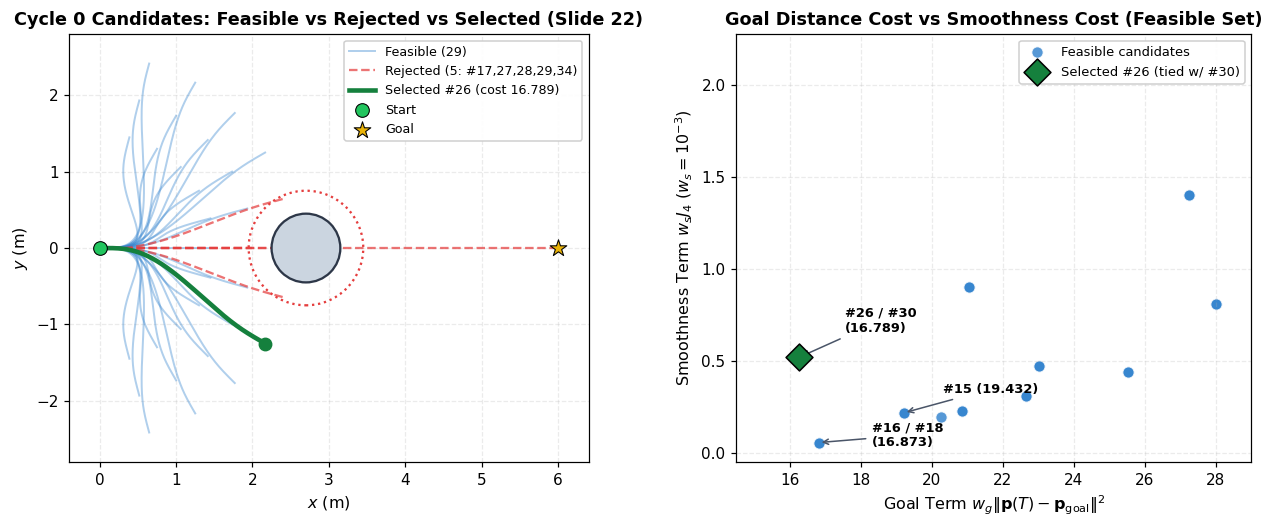

In [6]:
# =============================================================================
# Block 2 Demo: Cycle 0 Feasibility Audit, Slide 24 Ranking & 2-Panel Visual
# =============================================================================
sel_c0 = select_best_trajectory(
    coeffs_c0,
    T_c0,
    obs_center_lecture,
    obs_excl_lecture,
    p_goal_lecture,
    v_max=3.0,
    a_max=5.0,
    w_g=1.0,
    w_s=1e-3,
    w_T=0.0,
    n_eval=201,
)

feasible_np = np.asarray(sel_c0["feasible"])
clear_np = np.asarray(sel_c0["clear_obs"])
within_v_np = np.asarray(sel_c0["within_vel"])
within_a_np = np.asarray(sel_c0["within_acc"])
rejected_1b = [i + 1 for i in range(34) if not feasible_np[i]]
best_idx_0b = int(sel_c0["best_idx"])

print(f"{len(feasible_np)} candidates | {int(feasible_np.sum())} feasible | {int((~feasible_np).sum())} rejected")
print(f"Rejected candidates (1-based): {rejected_1b}")
assert int(feasible_np.sum()) == 29 and rejected_1b == [17, 27, 28, 29, 34]

for idx_0b in [i - 1 for i in rejected_1b]:
    print(
        f"  Rejected #{idx_0b + 1:2d}: "
        f"clear_obs={str(bool(clear_np[idx_0b])):5s} (min_d={float(sel_c0['min_center_dists'][idx_0b, 0]):.4f} m), "
        f"within_vel={str(bool(within_v_np[idx_0b])):5s} (max_v={float(sel_c0['max_speeds'][idx_0b]):.4f} m/s), "
        f"within_acc={str(bool(within_a_np[idx_0b])):5s} (max_a={float(sel_c0['max_accs'][idx_0b]):.4f} m/s^2)"
    )
assert (not clear_np[33]) and (not within_v_np[33]) and (not within_a_np[33])

# Build candidate metadata for Slide 24 comparison table
dist_list = [1.5, 2.0, 2.5]
ang_list = np.linspace(-75.0, 75.0, 11).tolist()
cand_meta = [(ell, ang) for ell in dist_list for ang in ang_list] + [(6.0, 0.0)]

feasible_ids = [i for i in range(34) if feasible_np[i]]
ranked_ids = sorted(feasible_ids, key=lambda i: (round(float(sel_c0["total_cost"][i]), 5), i))

print("\nTop-5 Feasible Candidates (Slide 24 Table):")
print(f"{'Cand':>6s} | {'ell (m)':>7s} | {'Angle':>7s} | {'Goal Term':>9s} | {'Snap Term':>9s} | {'Total Cost':>10s}")
print("-" * 62)
for i in ranked_ids[:5]:
    ell, ang = cand_meta[i]
    tag = " *" if i == best_idx_0b else ""
    print(
        f"#{i + 1:2d}{tag:<3s} | {ell:7.1f} | {ang:+6.1f}° | "
        f"{float(sel_c0['goal_term'][i]):9.3f} | {float(sel_c0['snap_term'][i]):9.3f} | "
        f"{float(sel_c0['total_cost'][i]):10.3f}"
    )

assert best_idx_0b == 25  # 1-based #26
assert [round(float(sel_c0["total_cost"][i]), 3) for i in ranked_ids[:5]] == [
    16.789, 16.789, 16.873, 16.873, 19.432
]

# 2-Panel Figure: Spatial Fan (Slide 22) + Goal vs Smoothness Scatter
pos_all, _, _ = eval_batch_pva(coeffs_c0, T_c0, n_eval=201)
pos_all_np = np.asarray(pos_all)
goal_terms_np = np.asarray(sel_c0["goal_term"])
snap_terms_np = np.asarray(sel_c0["snap_term"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.9), gridspec_kw={"width_ratios": [1.35, 1.0]})

# Left: Feasible vs Rejected vs Selected #26
lbl_feas_added = False
lbl_rej_added = False
for i in range(34):
    if i == best_idx_0b:
        continue
    if feasible_np[i]:
        ax1.plot(
            pos_all_np[i, :, 0], pos_all_np[i, :, 1],
            color="#3182ce", alpha=0.38, lw=1.3,
            label="Feasible (29)" if not lbl_feas_added else None,
        )
        lbl_feas_added = True
    else:
        ax1.plot(
            pos_all_np[i, :, 0], pos_all_np[i, :, 1],
            color="#e53e3e", ls="--", alpha=0.72, lw=1.5,
            label="Rejected (5: #17,27,28,29,34)" if not lbl_rej_added else None,
        )
        lbl_rej_added = True

ax1.plot(
    pos_all_np[best_idx_0b, :, 0], pos_all_np[best_idx_0b, :, 1],
    color="#15803d", lw=3.0, zorder=6, label="Selected #26 (cost 16.789)"
)
ax1.scatter(
    [pos_all_np[best_idx_0b, -1, 0]], [pos_all_np[best_idx_0b, -1, 1]],
    color="#15803d", s=65, zorder=7
)
ax1.add_patch(Circle(c_obs, r_obs, facecolor="#cbd5e0", edgecolor="#2d3748", lw=1.5, zorder=2))
ax1.add_patch(Circle(c_obs, float(obs_excl_lecture[0]), facecolor="none", edgecolor="#e53e3e", lw=1.5, ls=":", zorder=3))
ax1.scatter([0.0], [0.0], color="#22c55e", s=80, edgecolors="k", lw=0.7, zorder=8, label="Start")
ax1.scatter([6.0], [0.0], color="#eab308", s=130, marker="*", edgecolors="k", lw=0.7, zorder=8, label="Goal")
ax1.set_title("Cycle 0 Candidates: Feasible vs Rejected vs Selected (Slide 22)")
ax1.set_xlabel("$x$ (m)")
ax1.set_ylabel("$y$ (m)")
ax1.set_xlim(-0.4, 6.4)
ax1.set_ylim(-2.8, 2.8)
ax1.set_aspect("equal", adjustable="box")
ax1.legend(loc="upper right", fontsize=8.3, framealpha=0.94)

# Right: Goal Distance Cost vs Smoothness Cost scatter
feas_mask = feasible_np
ax2.scatter(
    goal_terms_np[feas_mask], snap_terms_np[feas_mask],
    color="#3182ce", s=55, alpha=0.82, edgecolors="white", lw=0.7, label="Feasible candidates"
)
# Highlight Selected #26 (note #30 ties at exact same coordinates)
ax2.scatter(
    [goal_terms_np[best_idx_0b]], [snap_terms_np[best_idx_0b]],
    color="#15803d", s=155, marker="D", edgecolors="k", lw=1.0, zorder=7,
    label="Selected #26 (tied w/ #30)"
)

for idx_ann, text_ann, dx, dy in [
    (25, "#26 / #30\n(16.789)", 1.3, 0.14),
    (15, "#16 / #18\n(16.873)", 1.5, -0.02),
    (14, "#15 (19.432)", 1.1, 0.11),
]:
    ax2.annotate(
        text_ann,
        xy=(goal_terms_np[idx_ann], snap_terms_np[idx_ann]),
        xytext=(goal_terms_np[idx_ann] + dx, snap_terms_np[idx_ann] + dy),
        arrowprops=dict(arrowstyle="->", color="#4a5568", lw=1.0),
        fontsize=8.5, fontweight="bold",
    )

ax2.set_title("Goal Distance Cost vs Smoothness Cost (Feasible Set)")
ax2.set_xlabel(r"Goal Term $w_g \|\mathbf{p}(T) - \mathbf{p}_{\mathrm{goal}}\|^2$")
ax2.set_ylabel(r"Smoothness Term $w_s J_4$ ($w_s = 10^{-3}$)")
ax2.set_xlim(14.5, 29.0)
ax2.set_ylim(-0.05, max(1.0, float(np.max(snap_terms_np[feas_mask])) * 1.15))
ax2.legend(loc="upper right", fontsize=8.5, framealpha=0.94)

plt.tight_layout()
plt.show()


---
## Part 3 — Final Receding-Horizon Sampling Planner

### 1. Receding-Horizon Loop & Jerk-Continuous Handoff (Slides 2, 18, 25–28)
Rather than flying an entire $T = 2.0\,\text{s}$ primitive open-loop, the drone executes only a short prefix $\Delta = 0.25\,\text{s}$ ($u_\Delta = \Delta / T$) and replans from the exact continuous endpoint state:
$$\mathbf{s}_{\text{new}} = \begin{bmatrix}\mathbf{p}(\Delta) \\ \dot{\mathbf{p}}(\Delta) \\ \ddot{\mathbf{p}}(\Delta) \\ \mathbf{p}^{(3)}(\Delta)\end{bmatrix}$$
Because position, velocity, acceleration, and jerk are carried across every cycle boundary, **motion remains $C^3$-continuous through jerk**, while **snap** $\mathbf{p}^{(4)}$ may jump cleanly at each $\Delta = 0.25\,\text{s}$ replanning tick.

### 2. Braking Contingency Fallback via `jax.lax.cond` (Slides 28–29)
If all $K$ sampled candidates fail feasibility (`has_feasible == False`), `plan_step_2d` / `plan_step_3d` branches inside XLA via `jax.lax.cond` to `compute_braking_primitive`, synthesizing a zero-terminal-motion stop ($\mathbf{v}_f=\mathbf{a}_f=\mathbf{j}_f=\mathbf{0}$) at $\mathbf{p}_f = \mathbf{p}_0 + \frac{1}{2}\mathbf{v}_0 T_{\text{brake}}$ and explicitly validating its clearance and kinematic limits before executing.

### 3. Pure-XLA Closed-Loop Rollouts (`jax.lax.scan` + `jax.vmap`)
Compiling the entire closed-loop planning mission inside `jax.lax.scan` (`rollout_fixed_horizon_2d`, `rollout_fixed_horizon_3d`) removes all Python loop overhead and lets `jax.vmap` evaluate dozens of randomized flights simultaneously in milliseconds.


In [7]:
# =============================================================================
# Block 3A: Receding-Horizon Sampling Planner Kernel (Pure JAX)
# =============================================================================
from collections.abc import Callable, Sequence
from typing import Any


def _state_float_dtype(state: jax.Array | np.ndarray) -> jnp.dtype:
    """Return floating dtype of ``state`` (falling back to JAX default float)."""
    arr = jnp.asarray(state)
    if jnp.issubdtype(arr.dtype, jnp.floating):
        return arr.dtype
    return jnp.asarray(1.0).dtype


@jax.jit
def compute_braking_primitive(
    state: jax.Array,
    T_brake: float | jax.Array,
) -> tuple[jax.Array, jax.Array]:
    """Construct a minimum-snap zero-terminal-motion braking contingency primitive."""
    dtype = _state_float_dtype(state)
    state_arr = jnp.asarray(state, dtype=dtype)
    T_arr = jnp.asarray(T_brake, dtype=dtype)
    pf_brake = state_arr[0] + state_arr[1] * (0.5 * T_arr)
    sf_brake = jnp.zeros_like(state_arr).at[0].set(pf_brake)
    coeffs_brake = compute_min_snap_coeffs(state_arr, sf_brake, T_arr)
    return coeffs_brake, T_arr


def _plan_step_from_candidates(
    state: jax.Array,
    coeffs_batch: jax.Array,
    T_batch: jax.Array,
    p_goal: jax.Array,
    obstacles_center: jax.Array,
    obstacles_excl_radius: jax.Array,
    T_brake: jax.Array,
    Delta: float | jax.Array,
    v_max: float,
    a_max: float,
    w_g: float,
    w_s: float,
    w_T: float,
    n_eval: int,
) -> tuple[
    jax.Array,
    jax.Array,
    jax.Array,
    jax.Array,
    jax.Array,
    dict[str, jax.Array],
]:
    """Shared selection, jax.lax.cond contingency fallback, and Delta-handoff update."""
    dtype = coeffs_batch.dtype
    selection_raw = select_best_trajectory(
        coeffs_batch,
        T_batch,
        obstacles_center,
        obstacles_excl_radius,
        p_goal,
        v_max=v_max,
        a_max=a_max,
        w_g=w_g,
        w_s=w_s,
        w_T=w_T,
        n_eval=n_eval,
    )
    fan_has_feasible = selection_raw["has_feasible"]
    fan_best_idx = selection_raw["best_idx"]
    T_brake_arr = jnp.asarray(T_brake, dtype=dtype)

    def _use_nominal(_: None) -> tuple[jax.Array, ...]:
        return (
            coeffs_batch[fan_best_idx],
            T_batch[fan_best_idx],
            jnp.asarray(False),
            jnp.asarray(True),
            jnp.asarray(True),
            jnp.asarray(True),
            jnp.asarray(True),
        )

    def _use_contingency(_: None) -> tuple[jax.Array, ...]:
        c_brake, T_b = compute_braking_primitive(state, T_brake_arr)
        res_brake = select_best_trajectory(
            c_brake[None, :, :],
            T_b[None],
            obstacles_center,
            obstacles_excl_radius,
            p_goal,
            v_max=v_max,
            a_max=a_max,
            w_g=w_g,
            w_s=w_s,
            w_T=w_T,
            n_eval=n_eval,
        )
        return (
            c_brake,
            T_b,
            jnp.asarray(True),
            res_brake["has_feasible"],
            res_brake["clear_obs"][0],
            res_brake["within_vel"][0],
            res_brake["within_acc"][0],
        )

    (
        best_coeffs,
        T_win,
        contingency_used,
        contingency_feasible,
        contingency_clear_obs,
        contingency_within_vel,
        contingency_within_acc,
    ) = jax.lax.cond(fan_has_feasible, _use_nominal, _use_contingency, operand=None)

    # Carry continuous state [p, v, a, j] at t = Delta into the next cycle (Slide 18).
    u_delta = jnp.asarray(Delta, dtype=dtype) / T_win
    p_next, v_next, a_next, j_next, _ = eval_primitive(best_coeffs, T_win, u_delta)
    next_state = jnp.stack([p_next, v_next, a_next, j_next], axis=0)
    best_idx = jnp.where(
        fan_has_feasible,
        fan_best_idx,
        jnp.asarray(-1, dtype=fan_best_idx.dtype),
    )

    selection_dict: dict[str, jax.Array] = {
        **selection_raw,
        "coeffs_batch": coeffs_batch,
        "T_batch": T_batch,
        "T_win": T_win,
        "contingency_used": contingency_used,
        "contingency_feasible": contingency_feasible,
        "contingency_clear_obs": contingency_clear_obs,
        "contingency_within_vel": contingency_within_vel,
        "contingency_within_acc": contingency_within_acc,
    }
    return (
        next_state,
        best_coeffs,
        best_idx,
        fan_has_feasible,
        contingency_used,
        selection_dict,
    )


@partial(jax.jit, static_argnames=("n_eval",))
def plan_step_2d(
    state: jax.Array,
    p_goal: jax.Array,
    obstacles_center: jax.Array,
    obstacles_excl_radius: jax.Array,
    angles_deg: jax.Array,
    distances: jax.Array,
    T: float = 2.0,
    Delta: float = 0.25,
    terminal_speed: float = 1.0,
    v_max: float = 3.0,
    a_max: float = 5.0,
    w_g: float = 1.0,
    w_s: float = 1e-3,
    w_T: float = 0.0,
    n_eval: int = 201,
) -> tuple[
    jax.Array,
    jax.Array,
    jax.Array,
    jax.Array,
    jax.Array,
    dict[str, jax.Array],
]:
    """Execute one fused XLA receding-horizon 2D planning cycle."""
    dtype = _state_float_dtype(state)
    state_arr = jnp.asarray(state, dtype=dtype)
    goal_arr = jnp.asarray(p_goal, dtype=dtype)
    obs_c_arr = jnp.asarray(obstacles_center, dtype=dtype)
    obs_r_arr = jnp.asarray(obstacles_excl_radius, dtype=dtype)
    ang_arr = jnp.asarray(angles_deg, dtype=dtype)
    dist_arr = jnp.asarray(distances, dtype=dtype)
    T_arr = jnp.asarray(T, dtype=dtype)

    coeffs_batch, T_batch = sample_candidates_2d(
        state_arr, goal_arr, ang_arr, dist_arr, T_arr, terminal_speed=terminal_speed
    )
    return _plan_step_from_candidates(
        state_arr, coeffs_batch, T_batch, goal_arr, obs_c_arr, obs_r_arr,
        T_arr, Delta, v_max, a_max, w_g, w_s, w_T, n_eval,
    )


@partial(jax.jit, static_argnames=("n_eval",))
def plan_step_3d(
    state: jax.Array,
    p_goal: jax.Array,
    obstacles_center: jax.Array,
    obstacles_excl_radius: jax.Array,
    az_angles_deg: jax.Array,
    el_angles_deg: jax.Array,
    distances: jax.Array,
    T: float = 2.0,
    Delta: float = 0.25,
    terminal_speed: float = 1.0,
    v_max: float = 3.0,
    a_max: float = 5.0,
    w_g: float = 1.0,
    w_s: float = 1e-3,
    w_T: float = 0.0,
    n_eval: int = 201,
) -> tuple[
    jax.Array,
    jax.Array,
    jax.Array,
    jax.Array,
    jax.Array,
    dict[str, jax.Array],
]:
    """Execute one fused XLA receding-horizon 3D planning cycle."""
    dtype = _state_float_dtype(state)
    state_arr = jnp.asarray(state, dtype=dtype)
    goal_arr = jnp.asarray(p_goal, dtype=dtype)
    obs_c_arr = jnp.asarray(obstacles_center, dtype=dtype)
    obs_r_arr = jnp.asarray(obstacles_excl_radius, dtype=dtype)
    az_arr = jnp.asarray(az_angles_deg, dtype=dtype)
    el_arr = jnp.asarray(el_angles_deg, dtype=dtype)
    dist_arr = jnp.asarray(distances, dtype=dtype)
    T_arr = jnp.asarray(T, dtype=dtype)

    coeffs_batch, T_batch = sample_candidates_3d(
        state_arr, goal_arr, az_arr, el_arr, dist_arr, T_arr, terminal_speed=terminal_speed
    )
    return _plan_step_from_candidates(
        state_arr, coeffs_batch, T_batch, goal_arr, obs_c_arr, obs_r_arr,
        T_arr, Delta, v_max, a_max, w_g, w_s, w_T, n_eval,
    )


def _compute_clearances(
    pos_np: np.ndarray,
    obs_c_np: np.ndarray,
    obs_excl_np: np.ndarray,
    obs_contact_np: np.ndarray,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Compute per-sample minimum center distance, exclusion margin, and surface clearance."""
    n_pts = pos_np.shape[0]
    if obs_c_np.shape[0] == 0:
        inf_arr = np.full((n_pts,), np.inf, dtype=pos_np.dtype)
        return inf_arr, inf_arr.copy(), inf_arr.copy()

    dists = np.linalg.norm(pos_np[:, None, :] - obs_c_np[None, :, :], axis=-1)
    return (
        np.min(dists, axis=1),
        np.min(dists - obs_excl_np[None, :], axis=1),
        np.min(dists - obs_contact_np[None, :], axis=1),
    )


def _run_mission_common(
    step_fn: Callable[[jax.Array], tuple[jax.Array, ...]],
    s0: jax.Array | np.ndarray,
    p_goal: jax.Array | np.ndarray,
    obstacles_center: jax.Array | np.ndarray,
    obstacles_excl_radius: jax.Array | np.ndarray,
    Delta: float,
    pos_tol: float,
    vel_tol: float,
    max_cycles: int,
    n_prefix_eval: int,
    obstacles_contact_radius: jax.Array | np.ndarray | None,
    snapshot_cycles: Sequence[int] | None,
) -> dict[str, Any]:
    """Shared closed-loop mission simulator recording dense trajectories and snapshots."""
    dtype = _state_float_dtype(s0)
    state = jnp.asarray(s0, dtype=dtype)
    goal_np = np.asarray(p_goal, dtype=np.float64)
    obs_c_np = np.asarray(obstacles_center, dtype=np.float64)
    obs_excl_np = np.asarray(obstacles_excl_radius, dtype=np.float64)
    obs_contact_np = (
        obs_excl_np
        if obstacles_contact_radius is None
        else np.asarray(obstacles_contact_radius, dtype=np.float64)
    )
    snapshot_set = None if snapshot_cycles is None else set(int(c) for c in snapshot_cycles)

    replan_states: list[np.ndarray] = [np.asarray(state)]
    replan_times: list[float] = [0.0]
    selected_indices: list[int] = []
    selected_coeffs: list[np.ndarray] = []
    cycle_times: list[float] = []
    contingency_cycles: list[int] = []
    segments: list[dict[str, np.ndarray | float | int]] = []
    snapshots: dict[int, dict[str, Any]] = {}

    status = "max_cycles"
    arrived = False

    for k in range(max_cycles):
        state_np = np.asarray(state, dtype=np.float64)
        pos_err = float(np.linalg.norm(state_np[0] - goal_np))
        speed = float(np.linalg.norm(state_np[1]))
        if pos_err <= pos_tol and speed <= vel_tol:
            arrived = True
            status = "arrived"
            break

        next_state, best_coeffs, best_idx, has_feasible, contingency_used, sel = step_fn(state)

        cont_used = bool(contingency_used)
        cont_feasible = bool(sel["contingency_feasible"])
        t_k = k * float(Delta)

        if snapshot_set is None or k in snapshot_set or (cont_used and not cont_feasible):
            snapshots[k] = {
                "cycle": k,
                "time": t_k,
                "state": np.asarray(state),
                "coeffs_batch": np.asarray(sel["coeffs_batch"]),
                "T_batch": np.asarray(sel["T_batch"]),
                "best_idx": int(best_idx),
                "best_coeffs": np.asarray(best_coeffs),
                "T_win": float(sel["T_win"]),
                "has_feasible": bool(has_feasible),
                "contingency_used": cont_used,
                "contingency_feasible": cont_feasible,
                "feasible": np.asarray(sel["feasible"]),
                "clear_obs": np.asarray(sel["clear_obs"]),
                "within_vel": np.asarray(sel["within_vel"]),
                "within_acc": np.asarray(sel["within_acc"]),
                "total_cost": np.asarray(sel["total_cost"]),
                "goal_term": np.asarray(sel["goal_term"]),
                "snap_term": np.asarray(sel["snap_term"]),
            }

        if cont_used and not cont_feasible:
            status = "contingency_failed"
            break
        if cont_used:
            contingency_cycles.append(k)

        T_win = sel["T_win"]
        u_seg = jnp.linspace(
            0.0,
            jnp.asarray(Delta, dtype=dtype) / T_win,
            n_prefix_eval,
            dtype=dtype,
        )
        p_seg, v_seg, a_seg, j_seg, s_seg = eval_primitive(best_coeffs, T_win, u_seg)
        p_seg_np = np.asarray(p_seg, dtype=np.float64)
        min_c, excl_m, surf_c = _compute_clearances(
            p_seg_np, obs_c_np, obs_excl_np, obs_contact_np
        )

        segments.append({
            "cycle": k,
            "t_start": t_k,
            "t_end": t_k + float(Delta),
            "t": np.linspace(t_k, t_k + float(Delta), n_prefix_eval),
            "pos": p_seg_np,
            "vel": np.asarray(v_seg, dtype=np.float64),
            "acc": np.asarray(a_seg, dtype=np.float64),
            "jerk": np.asarray(j_seg, dtype=np.float64),
            "snap": np.asarray(s_seg, dtype=np.float64),
            "min_center_dist": min_c,
            "excl_margin": excl_m,
            "surface_clearance": surf_c,
        })

        selected_indices.append(int(best_idx))
        selected_coeffs.append(np.asarray(best_coeffs))
        cycle_times.append(t_k)

        state = next_state
        replan_states.append(np.asarray(state))
        replan_times.append((k + 1) * float(Delta))
    else:
        state_np = np.asarray(state, dtype=np.float64)
        if float(np.linalg.norm(state_np[0] - goal_np)) <= pos_tol and float(np.linalg.norm(state_np[1])) <= vel_tol:
            arrived = True
            status = "arrived"

    num_cycles = len(segments)
    dim = int(np.asarray(s0).shape[1])

    if num_cycles > 0:
        def _cat_unique(key: str) -> np.ndarray:
            return np.concatenate([segments[0][key]] + [seg[key][1:] for seg in segments[1:]], axis=0)

        traj_t = _cat_unique("t")
        traj_pos = _cat_unique("pos")
        traj_vel = _cat_unique("vel")
        traj_acc = _cat_unique("acc")
        traj_jerk = _cat_unique("jerk")
        traj_snap = _cat_unique("snap")
        traj_min_center_dist = _cat_unique("min_center_dist")
        traj_excl_margin = _cat_unique("excl_margin")
        traj_surface_clearance = _cat_unique("surface_clearance")

        max_speed = float(np.max(np.linalg.norm(traj_vel, axis=-1)))
        max_acc = float(np.max(np.linalg.norm(traj_acc, axis=-1)))
        max_jerk = float(np.max(np.linalg.norm(traj_jerk, axis=-1)))
        max_snap = float(np.max(np.linalg.norm(traj_snap, axis=-1)))
        min_center_dist = float(np.min(traj_min_center_dist))
        min_excl_margin = float(np.min(traj_excl_margin))
        min_surface_clearance = float(np.min(traj_surface_clearance))
    else:
        traj_t = np.zeros((0,), dtype=np.float64)
        traj_pos = np.zeros((0, dim), dtype=np.float64)
        traj_vel = np.zeros((0, dim), dtype=np.float64)
        traj_acc = np.zeros((0, dim), dtype=np.float64)
        traj_jerk = np.zeros((0, dim), dtype=np.float64)
        traj_snap = np.zeros((0, dim), dtype=np.float64)
        traj_min_center_dist = np.zeros((0,), dtype=np.float64)
        traj_excl_margin = np.zeros((0,), dtype=np.float64)
        traj_surface_clearance = np.zeros((0,), dtype=np.float64)
        st0 = np.asarray(state, dtype=np.float64)
        max_speed = float(np.linalg.norm(st0[1]))
        max_acc = float(np.linalg.norm(st0[2]))
        max_jerk = float(np.linalg.norm(st0[3]))
        max_snap = 0.0
        c0, e0, s0_c = _compute_clearances(st0[0:1], obs_c_np, obs_excl_np, obs_contact_np)
        min_center_dist, min_excl_margin, min_surface_clearance = float(c0[0]), float(e0[0]), float(s0_c[0])

    final_state_np = np.asarray(state, dtype=np.float64)
    return {
        "arrived": arrived,
        "status": status,
        "num_cycles": num_cycles,
        "flight_time": float(num_cycles * float(Delta)),
        "final_state": final_state_np,
        "goal_error": float(np.linalg.norm(final_state_np[0] - goal_np)),
        "final_speed": float(np.linalg.norm(final_state_np[1])),
        "max_speed": max_speed,
        "max_acc": max_acc,
        "max_jerk": max_jerk,
        "max_snap": max_snap,
        "min_center_dist": min_center_dist,
        "min_excl_margin": min_excl_margin,
        "min_surface_clearance": min_surface_clearance,
        "contingency_cycles": contingency_cycles,
        "contingency_count": len(contingency_cycles),
        "replan_times": np.asarray(replan_times, dtype=np.float64),
        "replan_states": np.stack(replan_states, axis=0),
        "selected_indices": np.asarray(selected_indices, dtype=np.int32),
        "selected_coeffs": np.stack(selected_coeffs, axis=0) if selected_coeffs else np.zeros((0, 8, dim)),
        "cycle_times": np.asarray(cycle_times, dtype=np.float64),
        "traj_t": traj_t,
        "traj_pos": traj_pos,
        "traj_vel": traj_vel,
        "traj_acc": traj_acc,
        "traj_jerk": traj_jerk,
        "traj_snap": traj_snap,
        "traj_min_center_dist": traj_min_center_dist,
        "traj_excl_margin": traj_excl_margin,
        "traj_surface_clearance": traj_surface_clearance,
        "segments": segments,
        "snapshots": snapshots,
    }


def run_mission_2d(
    s0: jax.Array | np.ndarray,
    p_goal: jax.Array | np.ndarray,
    obstacles_center: jax.Array | np.ndarray,
    obstacles_excl_radius: jax.Array | np.ndarray,
    angles_deg: jax.Array | np.ndarray,
    distances: jax.Array | np.ndarray,
    T: float = 2.0,
    Delta: float = 0.25,
    terminal_speed: float = 1.0,
    v_max: float = 3.0,
    a_max: float = 5.0,
    w_g: float = 1.0,
    w_s: float = 1e-3,
    w_T: float = 0.0,
    n_eval: int = 201,
    pos_tol: float = 0.02,
    vel_tol: float = 0.02,
    max_cycles: int = 100,
    n_prefix_eval: int = 51,
    obstacles_contact_radius: jax.Array | np.ndarray | None = None,
    snapshot_cycles: Sequence[int] | None = None,
) -> dict[str, Any]:
    """Run closed-loop 2D receding-horizon mission simulation until convergence or stop."""
    dtype = _state_float_dtype(s0)
    goal_arr = jnp.asarray(p_goal, dtype=dtype)
    obs_c_arr = jnp.asarray(obstacles_center, dtype=dtype)
    obs_r_arr = jnp.asarray(obstacles_excl_radius, dtype=dtype)
    ang_arr = jnp.asarray(angles_deg, dtype=dtype)
    dist_arr = jnp.asarray(distances, dtype=dtype)

    def _step(st: jax.Array) -> tuple[jax.Array, ...]:
        return plan_step_2d(
            st, goal_arr, obs_c_arr, obs_r_arr, ang_arr, dist_arr,
            T=T, Delta=Delta, terminal_speed=terminal_speed,
            v_max=v_max, a_max=a_max, w_g=w_g, w_s=w_s, w_T=w_T, n_eval=n_eval,
        )

    return _run_mission_common(
        _step, s0, goal_arr, obs_c_arr, obs_r_arr, Delta,
        pos_tol, vel_tol, max_cycles, n_prefix_eval, obstacles_contact_radius, snapshot_cycles,
    )


def run_mission_3d(
    s0: jax.Array | np.ndarray,
    p_goal: jax.Array | np.ndarray,
    obstacles_center: jax.Array | np.ndarray,
    obstacles_excl_radius: jax.Array | np.ndarray,
    az_angles_deg: jax.Array | np.ndarray,
    el_angles_deg: jax.Array | np.ndarray,
    distances: jax.Array | np.ndarray,
    T: float = 2.0,
    Delta: float = 0.25,
    terminal_speed: float = 1.0,
    v_max: float = 3.0,
    a_max: float = 5.0,
    w_g: float = 1.0,
    w_s: float = 1e-3,
    w_T: float = 0.0,
    n_eval: int = 201,
    pos_tol: float = 0.02,
    vel_tol: float = 0.02,
    max_cycles: int = 100,
    n_prefix_eval: int = 51,
    obstacles_contact_radius: jax.Array | np.ndarray | None = None,
    snapshot_cycles: Sequence[int] | None = None,
) -> dict[str, Any]:
    """Run closed-loop 3D receding-horizon mission simulation until convergence or stop."""
    dtype = _state_float_dtype(s0)
    goal_arr = jnp.asarray(p_goal, dtype=dtype)
    obs_c_arr = jnp.asarray(obstacles_center, dtype=dtype)
    obs_r_arr = jnp.asarray(obstacles_excl_radius, dtype=dtype)
    az_arr = jnp.asarray(az_angles_deg, dtype=dtype)
    el_arr = jnp.asarray(el_angles_deg, dtype=dtype)
    dist_arr = jnp.asarray(distances, dtype=dtype)

    def _step(st: jax.Array) -> tuple[jax.Array, ...]:
        return plan_step_3d(
            st, goal_arr, obs_c_arr, obs_r_arr, az_arr, el_arr, dist_arr,
            T=T, Delta=Delta, terminal_speed=terminal_speed,
            v_max=v_max, a_max=a_max, w_g=w_g, w_s=w_s, w_T=w_T, n_eval=n_eval,
        )

    return _run_mission_common(
        _step, s0, goal_arr, obs_c_arr, obs_r_arr, Delta,
        pos_tol, vel_tol, max_cycles, n_prefix_eval, obstacles_contact_radius, snapshot_cycles,
    )


def _rollout_fixed_horizon_common(
    step_fn: Callable[[jax.Array], tuple[jax.Array, ...]],
    s0: jax.Array,
    p_goal: jax.Array,
    Delta: float,
    pos_tol: float,
    vel_tol: float,
    n_cycles: int,
    n_prefix_eval: int,
) -> dict[str, jax.Array]:
    """Shared pure-XLA ``jax.lax.scan`` fixed-horizon planner + simulator."""
    dtype = _state_float_dtype(s0)
    s0_arr = jnp.asarray(s0, dtype=dtype)
    goal_arr = jnp.asarray(p_goal, dtype=dtype)
    Delta_arr = jnp.asarray(Delta, dtype=dtype)
    dim = s0_arr.shape[1]

    def _is_at_goal(st: jax.Array) -> jax.Array:
        return (jnp.linalg.norm(st[0] - goal_arr) <= pos_tol) & (jnp.linalg.norm(st[1]) <= vel_tol)

    def _scan_body(carry: tuple[jax.Array, jax.Array], _: None) -> tuple[tuple[jax.Array, jax.Array], dict[str, jax.Array]]:
        state, done = carry
        done_before = done | _is_at_goal(state)

        cand_next_state, best_coeffs, best_idx, has_feasible, contingency_used, sel = step_fn(state)
        cont_feasible = sel["contingency_feasible"]
        cont_failed = contingency_used & (~cont_feasible)
        executed = (~done_before) & (~cont_failed)
        next_state = jnp.where(executed, cand_next_state, state)
        done_after = done_before | cont_failed | _is_at_goal(next_state)

        step_out: dict[str, jax.Array] = {
            "next_state": next_state,
            "best_coeffs": best_coeffs,
            "best_idx": best_idx,
            "has_feasible": has_feasible,
            "contingency_used": contingency_used,
            "contingency_feasible": cont_feasible,
            "executed": executed,
        }
        if n_prefix_eval > 0:
            u_grid = jnp.linspace(0.0, 1.0, n_prefix_eval, dtype=dtype) * (Delta_arr / sel["T_win"])
            p_seg, v_seg, a_seg, j_seg, s_seg = eval_primitive(best_coeffs, sel["T_win"], u_grid)
            hold_pos = jnp.broadcast_to(state[0], p_seg.shape)
            zeros_seg = jnp.zeros_like(p_seg)
            step_out.update({
                "traj_pos": jnp.where(executed, p_seg, hold_pos),
                "traj_vel": jnp.where(executed, v_seg, zeros_seg),
                "traj_acc": jnp.where(executed, a_seg, zeros_seg),
                "traj_jerk": jnp.where(executed, j_seg, zeros_seg),
                "traj_snap": jnp.where(executed, s_seg, zeros_seg),
            })
        else:
            empty = jnp.zeros((0, dim), dtype=dtype)
            step_out.update({k: empty for k in ("traj_pos", "traj_vel", "traj_acc", "traj_jerk", "traj_snap")})
        return (next_state, done_after), step_out

    init_carry = (s0_arr, _is_at_goal(s0_arr))
    (final_state, _), hist = jax.lax.scan(_scan_body, init_carry, None, length=n_cycles)

    return {
        "states": jnp.concatenate([s0_arr[None, :, :], hist["next_state"]], axis=0),
        "final_state": final_state,
        "best_coeffs": hist["best_coeffs"],
        "best_idx": hist["best_idx"],
        "has_feasible": hist["has_feasible"],
        "contingency_used": hist["contingency_used"],
        "contingency_feasible": hist["contingency_feasible"],
        "executed": hist["executed"],
        "num_executed_cycles": jnp.sum(hist["executed"].astype(jnp.int32)),
        "arrived": _is_at_goal(final_state),
        "goal_error": jnp.linalg.norm(final_state[0] - goal_arr),
        "final_speed": jnp.linalg.norm(final_state[1]),
        "traj_pos": hist["traj_pos"],
        "traj_vel": hist["traj_vel"],
        "traj_acc": hist["traj_acc"],
        "traj_jerk": hist["traj_jerk"],
        "traj_snap": hist["traj_snap"],
    }


@partial(jax.jit, static_argnames=("n_cycles", "n_eval", "n_prefix_eval"))
def rollout_fixed_horizon_2d(
    s0: jax.Array,
    p_goal: jax.Array,
    obstacles_center: jax.Array,
    obstacles_excl_radius: jax.Array,
    angles_deg: jax.Array,
    distances: jax.Array,
    T: float = 2.0,
    Delta: float = 0.25,
    terminal_speed: float = 1.0,
    v_max: float = 3.0,
    a_max: float = 5.0,
    w_g: float = 1.0,
    w_s: float = 1e-3,
    w_T: float = 0.0,
    pos_tol: float = 0.02,
    vel_tol: float = 0.02,
    n_cycles: int = 25,
    n_eval: int = 201,
    n_prefix_eval: int = 21,
) -> dict[str, jax.Array]:
    """Pure-XLA fixed-horizon 2D rollout using ``jax.lax.scan`` (``vmap``-ready)."""
    dtype = _state_float_dtype(s0)
    goal_arr = jnp.asarray(p_goal, dtype=dtype)
    obs_c_arr = jnp.asarray(obstacles_center, dtype=dtype)
    obs_r_arr = jnp.asarray(obstacles_excl_radius, dtype=dtype)
    ang_arr = jnp.asarray(angles_deg, dtype=dtype)
    dist_arr = jnp.asarray(distances, dtype=dtype)

    def _step(st: jax.Array) -> tuple[jax.Array, ...]:
        return plan_step_2d(
            st, goal_arr, obs_c_arr, obs_r_arr, ang_arr, dist_arr,
            T=T, Delta=Delta, terminal_speed=terminal_speed,
            v_max=v_max, a_max=a_max, w_g=w_g, w_s=w_s, w_T=w_T, n_eval=n_eval,
        )

    return _rollout_fixed_horizon_common(
        _step, s0, goal_arr, Delta, pos_tol, vel_tol, n_cycles, n_prefix_eval
    )


@partial(jax.jit, static_argnames=("n_cycles", "n_eval", "n_prefix_eval"))
def rollout_fixed_horizon_3d(
    s0: jax.Array,
    p_goal: jax.Array,
    obstacles_center: jax.Array,
    obstacles_excl_radius: jax.Array,
    az_angles_deg: jax.Array,
    el_angles_deg: jax.Array,
    distances: jax.Array,
    T: float = 2.0,
    Delta: float = 0.25,
    terminal_speed: float = 1.0,
    v_max: float = 3.0,
    a_max: float = 5.0,
    w_g: float = 1.0,
    w_s: float = 1e-3,
    w_T: float = 0.0,
    pos_tol: float = 0.02,
    vel_tol: float = 0.02,
    n_cycles: int = 35,
    n_eval: int = 201,
    n_prefix_eval: int = 21,
) -> dict[str, jax.Array]:
    """Pure-XLA fixed-horizon 3D rollout using ``jax.lax.scan`` (``vmap``-ready)."""
    dtype = _state_float_dtype(s0)
    goal_arr = jnp.asarray(p_goal, dtype=dtype)
    obs_c_arr = jnp.asarray(obstacles_center, dtype=dtype)
    obs_r_arr = jnp.asarray(obstacles_excl_radius, dtype=dtype)
    az_arr = jnp.asarray(az_angles_deg, dtype=dtype)
    el_arr = jnp.asarray(el_angles_deg, dtype=dtype)
    dist_arr = jnp.asarray(distances, dtype=dtype)

    def _step(st: jax.Array) -> tuple[jax.Array, ...]:
        return plan_step_3d(
            st, goal_arr, obs_c_arr, obs_r_arr, az_arr, el_arr, dist_arr,
            T=T, Delta=Delta, terminal_speed=terminal_speed,
            v_max=v_max, a_max=a_max, w_g=w_g, w_s=w_s, w_T=w_T, n_eval=n_eval,
        )

    return _rollout_fixed_horizon_common(
        _step, s0, goal_arr, Delta, pos_tol, vel_tol, n_cycles, n_prefix_eval
    )


print("Part 3 Block 3A planner kernel compiled and ready.")


Part 3 Block 3A planner kernel compiled and ready.


In [8]:
# =============================================================================
# Block 3A Demo: Lecture Mission (Slides 25-27), Continuity & Contingency Braking
# =============================================================================
mission_2d = run_mission_2d(
    s0_lecture,
    p_goal_lecture,
    obs_center_lecture,
    obs_excl_lecture,
    angles_lecture,
    distances_lecture,
    T=2.0,
    Delta=0.25,
    terminal_speed=1.0,
    v_max=3.0,
    a_max=5.0,
    w_g=1.0,
    w_s=1e-3,
    w_T=0.0,
    n_eval=201,
    pos_tol=0.02,
    vel_tol=0.02,
    max_cycles=60,
    n_prefix_eval=51,
    obstacles_contact_radius=obs_contact_lecture,
    snapshot_cycles=None,  # capture all cycles for diagnostics & animation
)

print("=== Lecture Mission Summary (Slide 27) ===")
print(
    f"Status: {mission_2d['status']} | Cycles: {mission_2d['num_cycles']} | "
    f"Flight Time: {mission_2d['flight_time']:.2f} s"
)
print(
    f"Goal Error: {mission_2d['goal_error']:.4f} m | "
    f"Final Speed: {mission_2d['final_speed']:.4f} m/s | "
    f"Min Surface Clearance: {mission_2d['min_surface_clearance']:.4f} m "
    f"(Excl Margin: {mission_2d['min_excl_margin']:.4f} m)"
)
print(
    f"Peak Kinematics: max_speed={mission_2d['max_speed']:.4f} m/s (<= 3.0), "
    f"max_acc={mission_2d['max_acc']:.4f} m/s^2 (<= 5.0), "
    f"contingency_count={mission_2d['contingency_count']}"
)

assert mission_2d["arrived"] and mission_2d["num_cycles"] == 23
assert round(mission_2d["goal_error"], 3) == 0.009
assert round(mission_2d["final_speed"], 3) == 0.001
assert round(mission_2d["min_surface_clearance"], 3) == 0.235

# Slide 26 Snapshots
print("\n=== Slide 26 Key Replanning Snapshots (t = 0.00 s, 1.50 s, 3.00 s) ===")
for cyc in (0, 6, 12):
    snap = mission_2d["snapshots"][cyc]
    st = snap["state"]
    pf_sel, _, _, _, _ = eval_primitive(jnp.asarray(snap["best_coeffs"]), snap["T_win"], 1.0)
    print(
        f"  Cycle {cyc:2d} (t={snap['time']:4.2f} s): p=({st[0,0]:.3f}, {st[0,1]:.3f}) m, "
        f"v=({st[1,0]:.3f}, {st[1,1]:.3f}) m/s, feasible={int(np.sum(snap['feasible']))}/34, "
        f"selected=#{snap['best_idx'] + 1} -> pf=({float(pf_sel[0]):.3f}, {float(pf_sel[1]):.3f}) m"
    )

# Slide 18 Junction Continuity across all 22 handoff boundaries
segs = mission_2d["segments"]
max_diffs = {"pos": 0.0, "vel": 0.0, "acc": 0.0, "jerk": 0.0}
snap_jumps = []
for k in range(len(segs) - 1):
    for key in max_diffs:
        max_diffs[key] = max(
            max_diffs[key],
            float(np.linalg.norm(segs[k + 1][key][0] - segs[k][key][-1])),
        )
    snap_jumps.append(float(np.linalg.norm(segs[k + 1]["snap"][0] - segs[k]["snap"][-1])))

print("\n=== Slide 18 Prefix-Boundary Continuity (22 Junctions) ===")
print(
    f"  max |dp|={max_diffs['pos']:.2e} m, max |dv|={max_diffs['vel']:.2e} m/s, "
    f"max |da|={max_diffs['acc']:.2e} m/s^2, max |dj|={max_diffs['jerk']:.2e} m/s^3"
)
print(f"  snap jump across junctions: min={min(snap_jumps):.3f}, max={max(snap_jumps):.3f} m/s^4")
assert max_diffs["pos"] < 1e-5 and max_diffs["jerk"] < 5e-4 and max(snap_jumps) > 1.0

# Contingency Braking Verification on Blocked Corridors (Slides 28-29)
print("\n=== Contingency Braking Verification (Slides 28-29) ===")
obs_c_block = jnp.array([
    [1.9,  0.0], [1.9,  0.9], [1.9, -0.9],
    [1.5,  1.3], [1.5, -1.3],
    [0.8,  1.4], [0.8, -1.4],
    [0.3,  1.4], [0.3, -1.4],
], dtype=jnp.float32)
obs_r_block = jnp.full((obs_c_block.shape[0],), 0.75, dtype=jnp.float32)

ns_blk, _, bidx_blk, feas_blk, cont_blk, sel_blk = plan_step_2d(
    s0_lecture, p_goal_lecture, obs_c_block, obs_r_block, angles_lecture, distances_lecture
)
assert (not bool(feas_blk)) and bool(cont_blk) and int(bidx_blk) == -1
assert bool(sel_blk["contingency_feasible"])
m_blk = run_mission_2d(
    s0_lecture, p_goal_lecture, obs_c_block, obs_r_block, angles_lecture, distances_lecture,
    max_cycles=30, obstacles_contact_radius=obs_r_block - 0.15,
)
print(
    f"  Case A (all 34 fan curves blocked, brake clear on step 0): "
    f"contingency_used={bool(cont_blk)}, brake_feasible={bool(sel_blk['contingency_feasible'])}, "
    f"v_next={float(jnp.linalg.norm(ns_blk[1])):.4f} m/s (< 1.0), "
    f"mission stop='{m_blk['status']}' after {m_blk['num_cycles']} cycle(s), "
    f"min_excl_margin={m_blk['min_excl_margin']:.4f} m"
)

obs_c_fatal = jnp.concatenate([obs_c_block, jnp.array([[1.1, 0.0]], dtype=jnp.float32)], axis=0)
obs_r_fatal = jnp.full((obs_c_fatal.shape[0],), 0.75, dtype=jnp.float32)
m_fatal = run_mission_2d(
    s0_lecture, p_goal_lecture, obs_c_fatal, obs_r_fatal, angles_lecture, distances_lecture
)
assert m_fatal["status"] == "contingency_failed" and m_fatal["num_cycles"] == 0
print(
    f"  Case B (wall inside braking path): halted cleanly at cycle {m_fatal['num_cycles']} "
    f"with status='{m_fatal['status']}'"
)


=== Lecture Mission Summary (Slide 27) ===
Status: arrived | Cycles: 23 | Flight Time: 5.75 s
Goal Error: 0.0088 m | Final Speed: 0.0013 m/s | Min Surface Clearance: 0.2348 m (Excl Margin: 0.0848 m)
Peak Kinematics: max_speed=1.5055 m/s (<= 3.0), max_acc=1.4065 m/s^2 (<= 5.0), contingency_count=0

=== Slide 26 Key Replanning Snapshots (t = 0.00 s, 1.50 s, 3.00 s) ===
  Cycle  0 (t=0.00 s): p=(0.000, 0.000) m, v=(1.000, 0.000) m/s, feasible=29/34, selected=#26 -> pf=(2.165, -1.250) m
  Cycle  6 (t=1.50 s): p=(1.769, -0.727) m, v=(1.337, -0.483) m/s, feasible=15/34, selected=#27 -> pf=(4.259, -0.956) m
  Cycle 12 (t=3.00 s): p=(3.853, -0.568) m, v=(1.361, 0.406) m/s, feasible=34/34, selected=#28 -> pf=(6.270, 0.071) m

=== Slide 18 Prefix-Boundary Continuity (22 Junctions) ===
  max |dp|=0.00e+00 m, max |dv|=0.00e+00 m/s, max |da|=0.00e+00 m/s^2, max |dj|=2.38e-07 m/s^3
  snap jump across junctions: min=0.031, max=32.144 m/s^4

=== Contingency Braking Verification (Slides 28-29) ===


  Case A (all 34 fan curves blocked, brake clear on step 0): contingency_used=True, brake_feasible=True, v_next=0.9839 m/s (< 1.0), mission stop='contingency_failed' after 1 cycle(s), min_excl_margin=0.6509 m


  Case B (wall inside braking path): halted cleanly at cycle 0 with status='contingency_failed'


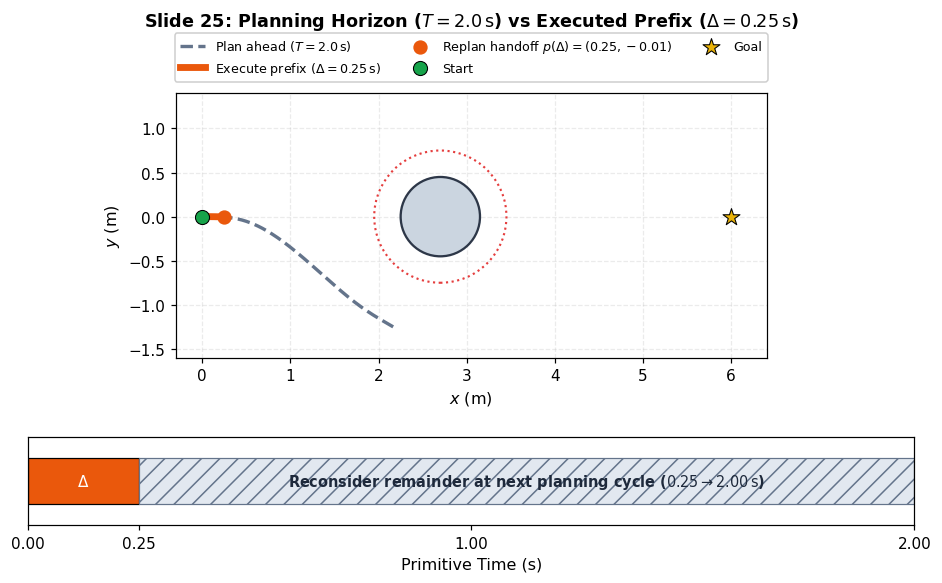

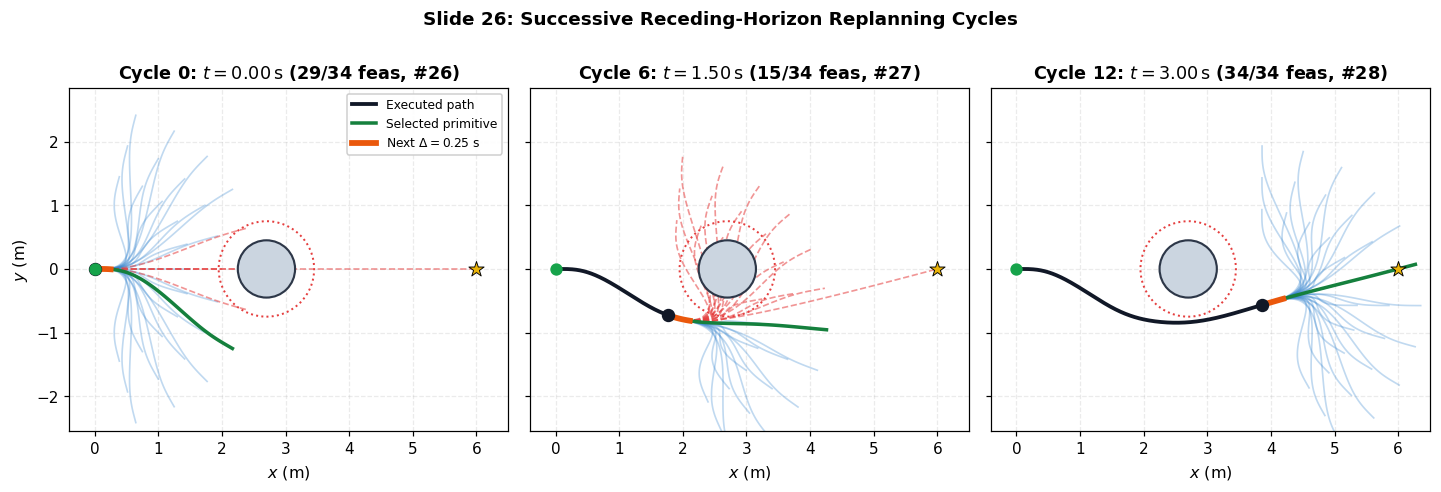

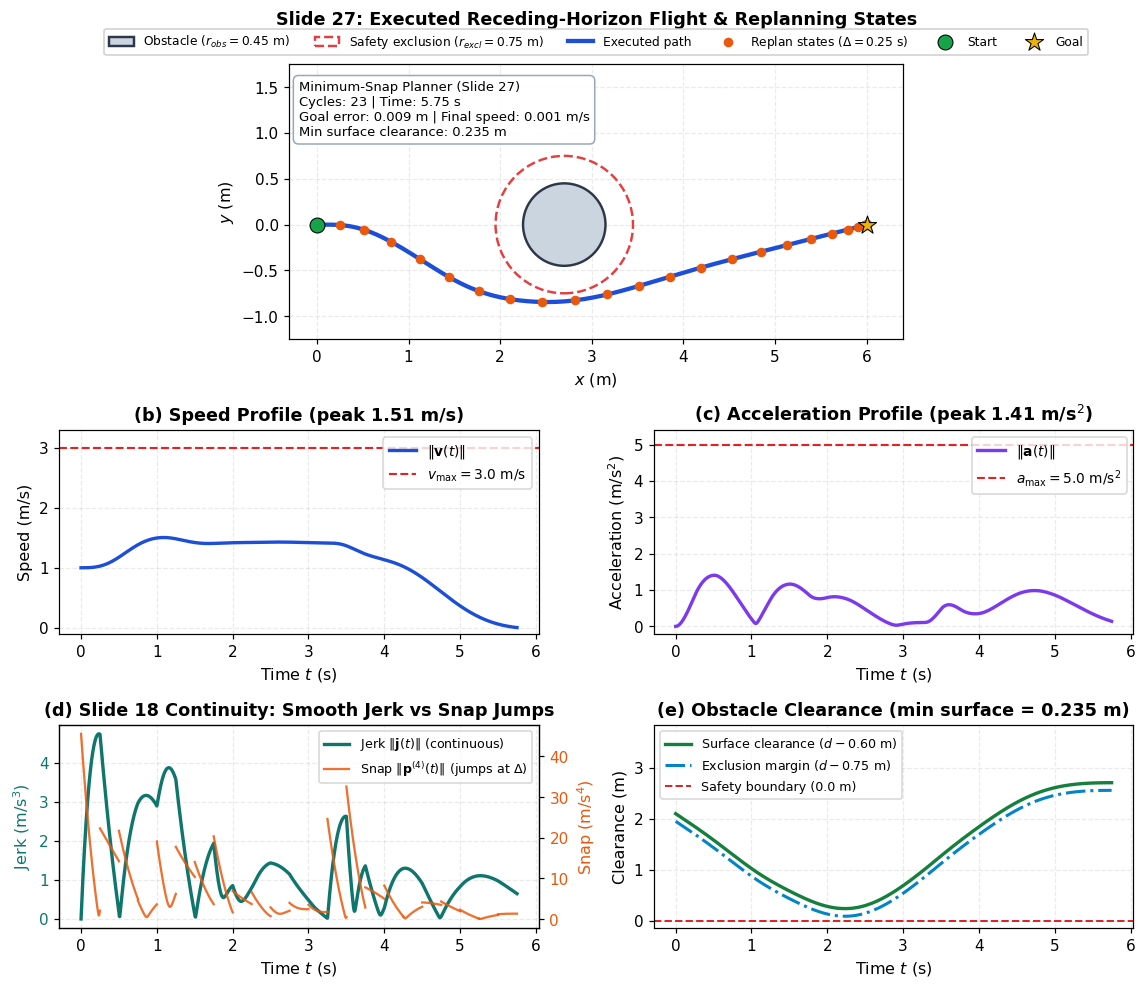

In [9]:
# =============================================================================
# Block 3B: Receding-Horizon Diagnostics (Slides 25, 26, 27 + Telemetry)
# =============================================================================
c_obs_2d = np.asarray(obs_center_lecture[0])

# -----------------------------------------------------------------------------
# Figure 1: Slide 25 — Planning Horizon T = 2 s vs Executed Prefix Delta = 0.25 s
# -----------------------------------------------------------------------------
snap0 = mission_2d["snapshots"][0]
u_full = jnp.linspace(0.0, 1.0, 201)
u_pref = jnp.linspace(0.0, 0.25 / snap0["T_win"], 51)
p_full0, _, _, _, _ = eval_primitive(jnp.asarray(snap0["best_coeffs"]), snap0["T_win"], u_full)
p_pref0, _, _, _, _ = eval_primitive(jnp.asarray(snap0["best_coeffs"]), snap0["T_win"], u_pref)
p_full0_np = np.asarray(p_full0)
p_pref0_np = np.asarray(p_pref0)

fig = plt.figure(figsize=(10.4, 5.1))
gs = fig.add_gridspec(2, 1, height_ratios=[3.0, 1.0], hspace=0.45)

ax = fig.add_subplot(gs[0])
ax.plot(p_full0_np[:, 0], p_full0_np[:, 1], color="#64748b", ls="--", lw=2.2,
        label="Plan ahead ($T = 2.0\\,\\mathrm{s}$)")
ax.plot(p_pref0_np[:, 0], p_pref0_np[:, 1], color="#ea580c", lw=4.5,
        label="Execute prefix ($\\Delta = 0.25\\,\\mathrm{s}$)")
ax.scatter([p_pref0_np[-1, 0]], [p_pref0_np[-1, 1]], color="#ea580c", s=70, zorder=7,
           label=f"Replan handoff $p(\\Delta)=({p_pref0_np[-1,0]:.2f}, {p_pref0_np[-1,1]:.2f})$")
ax.add_patch(Circle(c_obs_2d, r_obs, facecolor="#cbd5e0", edgecolor="#2d3748", lw=1.5, zorder=2))
ax.add_patch(Circle(c_obs_2d, float(obs_excl_lecture[0]), facecolor="none", edgecolor="#e53e3e", lw=1.4, ls=":", zorder=3))
ax.scatter([0.0], [0.0], color="#16a34a", s=85, edgecolors="k", lw=0.7, zorder=8, label="Start")
ax.scatter([6.0], [0.0], color="#eab308", s=135, marker="*", edgecolors="k", lw=0.7, zorder=8, label="Goal")
ax.set_title("Slide 25: Planning Horizon ($T = 2.0\\,\\mathrm{s}$) vs Executed Prefix ($\\Delta = 0.25\\,\\mathrm{s}$)", pad=44)
ax.set_xlabel("$x$ (m)")
ax.set_ylabel("$y$ (m)")
ax.set_xlim(-0.3, 6.4)
ax.set_ylim(-1.6, 1.4)
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3, fontsize=8.3, framealpha=0.95)

ax_t = fig.add_subplot(gs[1])
ax_t.barh([0], [0.25], left=[0.0], height=0.52, color="#ea580c", edgecolor="k", lw=0.8)
ax_t.barh([0], [1.75], left=[0.25], height=0.52, color="#e2e8f0", edgecolor="#64748b", lw=0.8, hatch="//")
ax_t.text(0.125, 0.0, "$\\Delta$", ha="center", va="center", color="white", fontweight="bold", fontsize=10)
ax_t.text(1.125, 0.0, "Reconsider remainder at next planning cycle ($0.25 \\to 2.00\\,\\mathrm{s}$)",
          ha="center", va="center", color="#1e293b", fontsize=9.5, fontweight="bold")
ax_t.set_xlim(0.0, 2.0)
ax_t.set_ylim(-0.5, 0.5)
ax_t.set_xticks([0.0, 0.25, 1.0, 2.0])
ax_t.set_yticks([])
ax_t.set_xlabel("Primitive Time (s)")
ax_t.grid(False)
plt.show()

# -----------------------------------------------------------------------------
# Figure 2: Slide 26 — 3-Panel Successive Planning Cycles (t = 0.00, 1.50, 3.00 s)
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.1), sharex=True, sharey=True)
traj_pos = mission_2d["traj_pos"]
traj_t = mission_2d["traj_t"]

for ax, cyc in zip(axes, (0, 6, 12)):
    snap = mission_2d["snapshots"][cyc]
    t_now = snap["time"]
    c_b = jnp.asarray(snap["coeffs_batch"])
    T_b = jnp.asarray(snap["T_batch"])
    feas = snap["feasible"]
    bidx = snap["best_idx"]

    p_b, _, _ = eval_batch_pva(c_b, T_b, n_eval=81)
    p_b_np = np.asarray(p_b)

    # Executed history up to t_now
    mask_hist = traj_t <= t_now + 1e-9
    ax.plot(traj_pos[mask_hist, 0], traj_pos[mask_hist, 1], color="#111827", lw=2.5, zorder=5, label="Executed path")

    for k in range(p_b_np.shape[0]):
        if k == bidx:
            continue
        col = "#3182ce" if feas[k] else "#e53e3e"
        ls = "-" if feas[k] else "--"
        alp = 0.30 if feas[k] else 0.55
        ax.plot(p_b_np[k, :, 0], p_b_np[k, :, 1], color=col, ls=ls, alpha=alp, lw=1.1)

    # Highlight selected primitive and its next Delta=0.25 s prefix
    p_sel = p_b_np[bidx]
    ax.plot(p_sel[:, 0], p_sel[:, 1], color="#15803d", lw=2.3, ls="-", zorder=6, label="Selected primitive")
    p_nx, _, _, _, _ = eval_primitive(jnp.asarray(snap["best_coeffs"]), snap["T_win"], u_pref)
    p_nx_np = np.asarray(p_nx)
    ax.plot(p_nx_np[:, 0], p_nx_np[:, 1], color="#ea580c", lw=3.8, zorder=7, label="Next $\\Delta=0.25$ s")

    ax.add_patch(Circle(c_obs_2d, r_obs, facecolor="#cbd5e0", edgecolor="#2d3748", lw=1.4, zorder=2))
    ax.add_patch(Circle(c_obs_2d, float(obs_excl_lecture[0]), facecolor="none", edgecolor="#e53e3e", lw=1.3, ls=":", zorder=3))
    st_now = snap["state"]
    ax.scatter([st_now[0, 0]], [st_now[0, 1]], color="#111827", s=60, zorder=8)
    ax.scatter([0.0], [0.0], color="#16a34a", s=50, zorder=8)
    ax.scatter([6.0], [0.0], color="#eab308", s=110, marker="*", edgecolors="k", lw=0.6, zorder=8)

    ax.set_title(f"Cycle {cyc}: $t = {t_now:.2f}\\,\\mathrm{{s}}$ ({int(np.sum(feas))}/34 feas, #{bidx + 1})")
    ax.set_xlabel("$x$ (m)")
    ax.set_xlim(-0.4, 6.5)
    ax.set_ylim(-2.55, 2.85)
    ax.set_aspect("equal", adjustable="box")

axes[0].set_ylabel("$y$ (m)")
axes[0].legend(loc="upper right", fontsize=8.0, framealpha=0.94)
fig.suptitle("Slide 26: Successive Receding-Horizon Replanning Cycles", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# Figure 3: Slide 27 Executed Flight & Full Kinematic / Continuity Dashboard
# -----------------------------------------------------------------------------
fig = plt.figure(figsize=(12.6, 10.2))
gs = fig.add_gridspec(3, 2, height_ratios=[1.35, 1.0, 1.0], hspace=0.40, wspace=0.24)

# Top span: Slide 27 Executed Route
ax_route = fig.add_subplot(gs[0, :])
ax_route.add_patch(Circle(c_obs_2d, r_obs, facecolor="#cbd5e0", edgecolor="#2d3748", lw=1.6, zorder=2, label="Obstacle ($r_{obs}=0.45$ m)"))
ax_route.add_patch(Circle(c_obs_2d, float(obs_excl_lecture[0]), facecolor="none", edgecolor="#e53e3e", lw=1.6, ls="--", zorder=3, label="Safety exclusion ($r_{excl}=0.75$ m)"))
ax_route.plot(traj_pos[:, 0], traj_pos[:, 1], color="#1d4ed8", lw=2.8, zorder=5, label="Executed path")
rep_p = mission_2d["replan_states"][:, 0, :]
ax_route.scatter(rep_p[:, 0], rep_p[:, 1], color="#ea580c", s=28, zorder=6, label="Replan states ($\\Delta=0.25$ s)")
ax_route.scatter([0.0], [0.0], color="#16a34a", s=95, edgecolors="k", lw=0.7, zorder=7, label="Start")
ax_route.scatter([6.0], [0.0], color="#eab308", s=155, marker="*", edgecolors="k", lw=0.7, zorder=7, label="Goal")
summary_txt = (
    f"Minimum-Snap Planner (Slide 27)\n"
    f"Cycles: {mission_2d['num_cycles']} | Time: {mission_2d['flight_time']:.2f} s\n"
    f"Goal error: {mission_2d['goal_error']:.3f} m | Final speed: {mission_2d['final_speed']:.3f} m/s\n"
    f"Min surface clearance: {mission_2d['min_surface_clearance']:.3f} m"
)
ax_route.text(
    0.015, 0.94, summary_txt, transform=ax_route.transAxes, va="top", fontsize=8.6,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#94a3b8", alpha=0.95),
)
ax_route.set_title("Slide 27: Executed Receding-Horizon Flight & Replanning States", pad=26)
ax_route.set_xlabel("$x$ (m)")
ax_route.set_ylabel("$y$ (m)")
ax_route.set_xlim(-0.3, 6.4)
ax_route.set_ylim(-1.25, 1.75)
ax_route.set_aspect("equal", adjustable="box")
ax_route.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=6, fontsize=8.0, framealpha=0.95)

# Telemetry (b): Speed
ax_v = fig.add_subplot(gs[1, 0])
spd = np.linalg.norm(mission_2d["traj_vel"], axis=-1)
ax_v.plot(traj_t, spd, color="#1d4ed8", lw=2.2, label=r"$\|\mathbf{v}(t)\|$")
ax_v.axhline(3.0, color="#dc2626", ls="--", lw=1.4, label="$v_{\\max} = 3.0$ m/s")
ax_v.set_title(f"(b) Speed Profile (peak {mission_2d['max_speed']:.2f} m/s)")
ax_v.set_xlabel("Time $t$ (s)")
ax_v.set_ylabel("Speed (m/s)")
ax_v.set_ylim(-0.1, 3.3)
ax_v.legend(loc="upper right")

# Telemetry (c): Acceleration
ax_a = fig.add_subplot(gs[1, 1])
acc_n = np.linalg.norm(mission_2d["traj_acc"], axis=-1)
ax_a.plot(traj_t, acc_n, color="#7c3aed", lw=2.2, label=r"$\|\mathbf{a}(t)\|$")
ax_a.axhline(5.0, color="#dc2626", ls="--", lw=1.4, label="$a_{\\max} = 5.0$ m/s$^2$")
ax_a.set_title(f"(c) Acceleration Profile (peak {mission_2d['max_acc']:.2f} m/s$^2$)")
ax_a.set_xlabel("Time $t$ (s)")
ax_a.set_ylabel("Acceleration (m/s$^2$)")
ax_a.set_ylim(-0.2, 5.4)
ax_a.legend(loc="upper right")

# Telemetry (d): Jerk Continuity vs Snap Jumps (Slide 18)
ax_js = fig.add_subplot(gs[2, 0])
jerk_n = np.linalg.norm(mission_2d["traj_jerk"], axis=-1)
snap_n = np.linalg.norm(mission_2d["traj_snap"], axis=-1)
ax_js.plot(traj_t, jerk_n, color="#0f766e", lw=2.2, label=r"Jerk $\|\mathbf{j}(t)\|$ (continuous)")
ax_js.set_xlabel("Time $t$ (s)")
ax_js.set_ylabel(r"Jerk (m/s$^3$)", color="#0f766e")
ax_js.tick_params(axis="y", labelcolor="#0f766e")

ax_s2 = ax_js.twinx()
# Plot per-segment snap cleanly so junction discontinuities are visibly sharp
for seg in mission_2d["segments"]:
    sn_seg = np.linalg.norm(seg["snap"], axis=-1)
    lbl = r"Snap $\|\mathbf{p}^{(4)}(t)\|$ (jumps at $\Delta$)" if seg["cycle"] == 0 else None
    ax_s2.plot(seg["t"], sn_seg, color="#ea580c", lw=1.5, alpha=0.85, label=lbl)
ax_s2.set_ylabel(r"Snap (m/s$^4$)", color="#ea580c")
ax_s2.tick_params(axis="y", labelcolor="#ea580c")
ax_s2.grid(False)
ax_js.set_title("(d) Slide 18 Continuity: Smooth Jerk vs Snap Jumps")
lines1, labels1 = ax_js.get_legend_handles_labels()
lines2, labels2 = ax_s2.get_legend_handles_labels()
ax_js.legend(lines1 + lines2, labels1 + labels2, loc="upper right", fontsize=8.3)

# Telemetry (e): Obstacle Surface Clearance & Exclusion Margin
ax_c = fig.add_subplot(gs[2, 1])
ax_c.plot(traj_t, mission_2d["traj_surface_clearance"], color="#15803d", lw=2.2, label="Surface clearance ($d - 0.60$ m)")
ax_c.plot(traj_t, mission_2d["traj_excl_margin"], color="#0284c7", lw=2.0, ls="-.", label="Exclusion margin ($d - 0.75$ m)")
ax_c.axhline(0.0, color="#dc2626", ls="--", lw=1.3, label="Safety boundary (0.0 m)")
ax_c.set_title(f"(e) Obstacle Clearance (min surface = {mission_2d['min_surface_clearance']:.3f} m)")
ax_c.set_xlabel("Time $t$ (s)")
ax_c.set_ylabel("Clearance (m)")
ax_c.set_ylim(-0.15, 3.85)
ax_c.legend(loc="upper left", fontsize=8.3)

plt.show()


In [10]:
# =============================================================================
# Block 3B: Closed-Loop 2D Planning Animation (mediapy @ 20 FPS, 640x400)
# =============================================================================
fig_anim, ax_anim = plt.subplots(figsize=(6.4, 4.0), dpi=100)

frames = []
sub_per_cycle = 5  # Delta=0.25 s * 20 fps = 5 frames/cycle -> 1x real-time playback
u_fan_anim = jnp.linspace(0.0, 1.0, 51)
traj_pos_full = mission_2d["traj_pos"]
traj_t_full = mission_2d["traj_t"]
c_obs_anim = np.asarray(obs_center_lecture[0])

for cyc in range(mission_2d["num_cycles"]):
    snap = mission_2d["snapshots"][cyc]
    seg = mission_2d["segments"][cyc]

    c_b = jnp.asarray(snap["coeffs_batch"])
    T_b = jnp.asarray(snap["T_batch"])
    feas = snap["feasible"]
    bidx = snap["best_idx"]

    p_b, _, _ = eval_batch_pva(c_b, T_b, n_eval=51)
    p_b_np = np.asarray(p_b)
    p_sel = p_b_np[bidx]

    sub_indices = np.linspace(0, len(seg["t"]) - 1, sub_per_cycle, endpoint=False, dtype=int)
    for idx_s in sub_indices:
        t_cur = float(seg["t"][idx_s])
        p_cur = seg["pos"][idx_s]
        v_cur = seg["vel"][idx_s]
        spd_cur = float(np.linalg.norm(v_cur))
        clr_cur = float(seg["surface_clearance"][idx_s])

        ax_anim.clear()
        ax_anim.grid(True, alpha=0.25, linestyle="--")

        # Live candidate fan from current cycle
        for k in range(p_b_np.shape[0]):
            if k == bidx:
                continue
            col = "#60a5fa" if feas[k] else "#f87171"
            ls = "-" if feas[k] else "--"
            alp = 0.28 if feas[k] else 0.50
            ax_anim.plot(p_b_np[k, :, 0], p_b_np[k, :, 1], color=col, ls=ls, alpha=alp, lw=1.0)

        # Selected horizon + cycle execution prefix
        ax_anim.plot(p_sel[:, 0], p_sel[:, 1], color="#16a34a", lw=2.0, alpha=0.85, label="Selected horizon")
        ax_anim.plot(seg["pos"][:, 0], seg["pos"][:, 1], color="#ea580c", lw=3.0, alpha=0.85, label="Active $\\Delta$ prefix")

        # Executed trail up to t_cur
        mask_t = traj_t_full <= t_cur + 1e-9
        ax_anim.plot(traj_pos_full[mask_t, 0], traj_pos_full[mask_t, 1], color="#1e3a8a", lw=2.5, label="Executed path")

        # Obstacle & safety halo
        ax_anim.add_patch(Circle(c_obs_anim, r_obs, facecolor="#cbd5e0", edgecolor="#1e293b", lw=1.4, zorder=2))
        ax_anim.add_patch(Circle(c_obs_anim, float(obs_excl_lecture[0]), facecolor="none", edgecolor="#dc2626", lw=1.3, ls=":", zorder=3))
        ax_anim.scatter([0.0], [0.0], color="#16a34a", s=50, zorder=5)
        ax_anim.scatter([6.0], [0.0], color="#eab308", s=110, marker="*", edgecolors="k", lw=0.6, zorder=6)

        # Drone body + velocity arrow
        ax_anim.scatter([p_cur[0]], [p_cur[1]], color="#111827", s=65, zorder=8)
        ax_anim.quiver(
            p_cur[0], p_cur[1], v_cur[0] * 0.38, v_cur[1] * 0.38,
            angles="xy", scale_units="xy", scale=1, color="#ea580c", width=0.010, zorder=9
        )

        ax_anim.set_title("Receding-Horizon Minimum-Snap Planning (Closed Loop)", fontsize=10.5, fontweight="bold")
        ax_anim.set_xlabel("$x$ (m)", fontsize=9.5)
        ax_anim.set_ylabel("$y$ (m)", fontsize=9.5)
        ax_anim.set_xlim(-0.4, 6.4)
        ax_anim.set_ylim(-2.4, 2.65)
        ax_anim.set_aspect("equal", adjustable="box")

        hud = (
            f"Cycle {cyc:02d}/{mission_2d['num_cycles']} | t = {t_cur:.2f} s\n"
            f"Feasible: {int(np.sum(feas))}/34 | Sel #{bidx + 1}\n"
            f"Speed: {spd_cur:.2f} m/s | Clr: {clr_cur:.2f} m"
        )
        ax_anim.text(
            0.02, 0.96, hud, transform=ax_anim.transAxes, va="top", fontsize=8.3,
            bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="#94a3b8", alpha=0.92),
        )
        fig_anim.tight_layout(pad=0.6)
        fig_anim.canvas.draw()
        rgb = np.asarray(fig_anim.canvas.buffer_rgba(), dtype=np.uint8)[:, :, :3].copy()
        frames.append(rgb)

# Append 10 brief hold frames at goal
for _ in range(10):
    frames.append(frames[-1])

plt.close(fig_anim)
print(f"Rendered {len(frames)} frames at {frames[0].shape[1]}x{frames[0].shape[0]} ({len(frames)/20.0:.2f} s @ 20 FPS)")
media.show_video(frames, fps=20)


Rendered 125 frames at 640x400 (6.25 s @ 20 FPS)


This browser does not support the video tag.


### Block 3C — Scaling with JAX: XLA Rollouts, `jax.vmap` Parallelization & 3D Corridor Flight

Because `plan_step_2d` and `plan_step_3d` are pure JAX functions with static grid shapes, we can:
1. Compile an entire 25-cycle receding-horizon mission into **one fused XLA graph** via `jax.lax.scan` (`rollout_fixed_horizon_2d`).
2. Vectorize over **64 randomized missions simultaneously** using `jax.vmap` $\times$ `jax.lax.scan` ($64 \times 25 = 1,600$ planning cycles in a single XLA dispatch!).
3. Scale seamlessly to **3D cluttered environments** ($M = 6$ spherical obstacles, 9 azimuth $\times$ 5 elevation $\times$ 3 distances + goal = **136 candidates/cycle**).


=== XLA Benchmarks on GPU (cuda:0) ===
  1. Single-cycle plan_step_2d (34 cands):   compile=1177.0 ms | warm=0.2055 ms
  2. 25-cycle lax.scan 2D rollout:          compile=1531.7 ms | warm=2.175 ms
  3. 64-mission vmap x lax.scan (1600 cyc): compile=2179.0 ms | warm=1.243 ms (0.0194 ms/mission)
     -> Batch arrived: 63/64 | Global min excl margin: 0.0132 m
  4. 35-cycle lax.scan 3D rollout (136 c):  compile=1854.7 ms | warm=2.713 ms

=== 3D 6-Obstacle Corridor Flight Summary ===
  Status: arrived | Cycles: 30 | Time: 7.50 s | Cands/cycle: 136
  Goal Error: 0.0085 m | Final Speed: 0.0017 m/s | Min Surface Clearance: 0.1607 m | Min Excl Margin: 0.0107 m


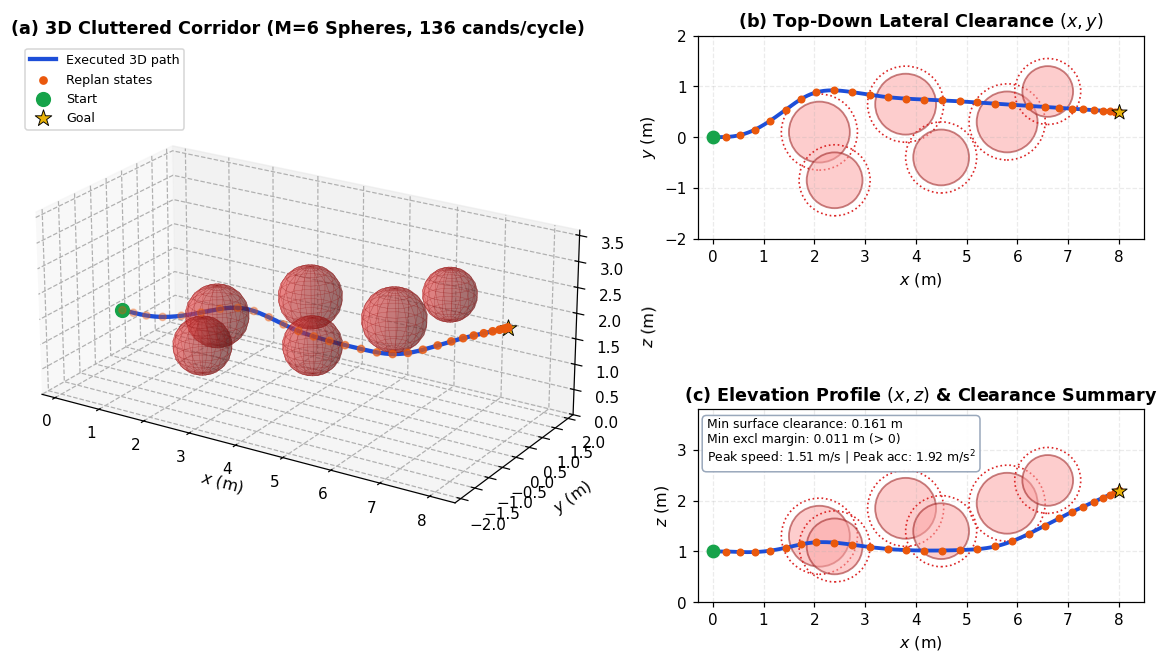

In [11]:
# =============================================================================
# Block 3C: XLA GPU/CPU Benchmarks + 3D Multi-Obstacle Cluttered Corridor (M=6)
# =============================================================================
import time


def _bench_jax(fn, *args, n_runs: int = 50, **kwargs):
    t0 = time.perf_counter()
    out = fn(*args, **kwargs)
    jax.block_until_ready(out)
    compile_ms = (time.perf_counter() - t0) * 1e3

    t1 = time.perf_counter()
    for _ in range(n_runs):
        out = fn(*args, **kwargs)
    jax.block_until_ready(out)
    warm_ms = (time.perf_counter() - t1) * 1e3 / n_runs
    return compile_ms, warm_ms, out


# 1. Single-cycle plan_step_2d benchmark
c_step_ms, w_step_ms, _ = _bench_jax(
    plan_step_2d,
    s0_lecture, p_goal_lecture, obs_center_lecture, obs_excl_lecture,
    angles_lecture, distances_lecture, n_runs=200,
)

# 2. Full 25-cycle lax.scan 2D rollout + exact equivalence check vs Python loop
c_scan_ms, w_scan_ms, scan2d_out = _bench_jax(
    rollout_fixed_horizon_2d,
    s0_lecture, p_goal_lecture, obs_center_lecture, obs_excl_lecture,
    angles_lecture, distances_lecture, n_cycles=25, n_eval=201, n_prefix_eval=21, n_runs=100,
)
assert bool(scan2d_out["arrived"]) and int(scan2d_out["num_executed_cycles"]) == 23
assert np.allclose(np.asarray(scan2d_out["states"][:24]), mission_2d["replan_states"], atol=1e-6)

# 3. 64-mission jax.vmap x jax.lax.scan parallel rollout (1600 planning cycles)
B = 64
rng = np.random.default_rng(123)
s0_batch = np.repeat(np.asarray(s0_lecture)[None, :, :], B, axis=0)
s0_batch[:, 0, 1] = rng.uniform(-0.35, 0.35, size=B)
s0_batch[:, 1, 0] = rng.uniform(0.6, 1.4, size=B)
s0_batch[:, 1, 1] = rng.uniform(-0.25, 0.25, size=B)
goal_batch = np.repeat(np.asarray(p_goal_lecture)[None, :], B, axis=0)
goal_batch[:, 1] = rng.uniform(-0.4, 0.4, size=B)
obs_c_batch = np.repeat(np.asarray(obs_center_lecture)[None, :, :], B, axis=0)
obs_c_batch[:, 0, 0] += rng.uniform(-0.25, 0.25, size=B)
obs_c_batch[:, 0, 1] += rng.uniform(-0.20, 0.20, size=B)

@jax.jit
def batch_rollout_64(s0_b, g_b, oc_b):
    return jax.vmap(
        lambda s, g, oc: rollout_fixed_horizon_2d(
            s, g, oc, obs_excl_lecture, angles_lecture, distances_lecture,
            n_cycles=25, n_eval=201, n_prefix_eval=21,
        )
    )(s0_b, g_b, oc_b)

c_vmap_ms, w_vmap_ms, vmap64_out = _bench_jax(
    batch_rollout_64,
    jnp.asarray(s0_batch, dtype=jnp.float32),
    jnp.asarray(goal_batch, dtype=jnp.float32),
    jnp.asarray(obs_c_batch, dtype=jnp.float32),
    n_runs=50,
)
n_arrived_64 = int(jnp.sum(vmap64_out["arrived"]))
pos_64 = np.asarray(vmap64_out["traj_pos"])
d_64 = np.linalg.norm(pos_64 - obs_c_batch[:, None, :, :], axis=-1)
min_excl_64 = float(np.min(d_64 - float(obs_excl_lecture[0])))
assert n_arrived_64 >= 55 and min_excl_64 > -1e-6

# 4. 3D Cluttered Corridor (M=6 spheres, 136 candidates/cycle)
s0_3d = jnp.array([[0.0, 0.0, 1.0], [1.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0, 0.0]], dtype=jnp.float32)
p_goal_3d = jnp.array([8.0, 0.5, 2.2], dtype=jnp.float32)
obs_c_3d = jnp.array([
    [2.1,  0.10, 1.30],
    [2.4, -0.85, 1.10],
    [3.8,  0.65, 1.85],
    [4.5, -0.40, 1.40],
    [5.8,  0.30, 1.95],
    [6.6,  0.90, 2.40],
], dtype=jnp.float32)
obs_excl_3d = jnp.array([0.75, 0.70, 0.75, 0.70, 0.75, 0.65], dtype=jnp.float32)
obs_contact_3d = obs_excl_3d - 0.15
az_3d = jnp.asarray(np.linspace(-60.0, 60.0, 9), dtype=jnp.float32)
el_3d = jnp.asarray(np.linspace(-30.0, 30.0, 5), dtype=jnp.float32)
dist_3d = jnp.array([1.5, 2.0, 2.5], dtype=jnp.float32)

c_scan3d_ms, w_scan3d_ms, scan3d_out = _bench_jax(
    rollout_fixed_horizon_3d,
    s0_3d, p_goal_3d, obs_c_3d, obs_excl_3d, az_3d, el_3d, dist_3d,
    n_cycles=35, n_eval=201, n_prefix_eval=21, n_runs=50,
)

mission_3d = run_mission_3d(
    s0_3d, p_goal_3d, obs_c_3d, obs_excl_3d, az_3d, el_3d, dist_3d,
    T=2.0, Delta=0.25, terminal_speed=1.0, v_max=3.0, a_max=5.0,
    w_g=1.0, w_s=1e-3, w_T=0.0, n_eval=201, pos_tol=0.02, vel_tol=0.02,
    max_cycles=80, n_prefix_eval=51, obstacles_contact_radius=obs_contact_3d,
)
assert mission_3d["arrived"] and mission_3d["min_excl_margin"] > 0.0

print(f"=== XLA Benchmarks on {jax.default_backend().upper()} ({jax.devices()[0]}) ===")
print(f"  1. Single-cycle plan_step_2d (34 cands):   compile={c_step_ms:6.1f} ms | warm={w_step_ms:.4f} ms")
print(f"  2. 25-cycle lax.scan 2D rollout:          compile={c_scan_ms:6.1f} ms | warm={w_scan_ms:.3f} ms")
print(f"  3. 64-mission vmap x lax.scan (1600 cyc): compile={c_vmap_ms:6.1f} ms | warm={w_vmap_ms:.3f} ms ({w_vmap_ms/B:.4f} ms/mission)")
print(f"     -> Batch arrived: {n_arrived_64}/64 | Global min excl margin: {min_excl_64:.4f} m")
print(f"  4. 35-cycle lax.scan 3D rollout (136 c):  compile={c_scan3d_ms:6.1f} ms | warm={w_scan3d_ms:.3f} ms")

print("\n=== 3D 6-Obstacle Corridor Flight Summary ===")
print(
    f"  Status: {mission_3d['status']} | Cycles: {mission_3d['num_cycles']} | "
    f"Time: {mission_3d['flight_time']:.2f} s | Cands/cycle: {mission_3d['snapshots'][0]['coeffs_batch'].shape[0]}"
)
print(
    f"  Goal Error: {mission_3d['goal_error']:.4f} m | Final Speed: {mission_3d['final_speed']:.4f} m/s | "
    f"Min Surface Clearance: {mission_3d['min_surface_clearance']:.4f} m | "
    f"Min Excl Margin: {mission_3d['min_excl_margin']:.4f} m"
)

# Dual-View 3D Trajectory + Obstacle Spheres + Lateral/Elevation Clearance Figure
fig = plt.figure(figsize=(13.2, 7.6))
gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 1.0], height_ratios=[1.0, 1.0], wspace=0.24, hspace=0.34)

# (a) 3D Perspective View with Obstacle Spheres
ax3d = fig.add_subplot(gs[:, 0], projection="3d")
p3 = mission_3d["traj_pos"]
rep3 = mission_3d["replan_states"][:, 0, :]
obs_c3_np = np.asarray(obs_c_3d)
obs_r_cont_np = np.asarray(obs_contact_3d)
obs_r_excl_np = np.asarray(obs_excl_3d)

u_s, v_s = np.mgrid[0:2*np.pi:20j, 0:np.pi:12j]
sx, sy, sz = np.cos(u_s)*np.sin(v_s), np.sin(u_s)*np.sin(v_s), np.cos(v_s)
for m in range(obs_c3_np.shape[0]):
    cx, cy, cz = obs_c3_np[m]
    rc = obs_r_cont_np[m]
    ax3d.plot_surface(cx + rc*sx, cy + rc*sy, cz + rc*sz, color="#ef4444", alpha=0.38, edgecolor="#991b1b", lw=0.25)

ax3d.plot(p3[:, 0], p3[:, 1], p3[:, 2], color="#1d4ed8", lw=2.8, label="Executed 3D path")
ax3d.scatter(rep3[:, 0], rep3[:, 1], rep3[:, 2], color="#ea580c", s=22, label="Replan states")
ax3d.scatter([0.0], [0.0], [1.0], color="#16a34a", s=80, label="Start")
ax3d.scatter([float(p_goal_3d[0])], [float(p_goal_3d[1])], [float(p_goal_3d[2])],
             color="#eab308", s=130, marker="*", edgecolors="k", lw=0.6, label="Goal")
ax3d.set_title("(a) 3D Cluttered Corridor (M=6 Spheres, 136 cands/cycle)")
ax3d.set_xlabel("$x$ (m)")
ax3d.set_ylabel("$y$ (m)")
ax3d.set_zlabel("$z$ (m)")
ax3d.set_xlim(-0.3, 8.5)
ax3d.set_ylim(-2.2, 2.2)
ax3d.set_zlim(0.0, 3.6)
ax3d.set_box_aspect((8.8, 4.4, 3.6))
ax3d.view_init(elev=22, azim=-58)
ax3d.legend(loc="upper left", fontsize=8.3)

# (b) Lateral Top-Down (x, y) View
ax_xy = fig.add_subplot(gs[0, 1])
for m in range(obs_c3_np.shape[0]):
    ax_xy.add_patch(Circle(obs_c3_np[m, :2], obs_r_cont_np[m], facecolor="#fca5a5", edgecolor="#991b1b", alpha=0.55, lw=1.2))
    ax_xy.add_patch(Circle(obs_c3_np[m, :2], obs_r_excl_np[m], facecolor="none", edgecolor="#dc2626", ls=":", lw=1.1))
ax_xy.plot(p3[:, 0], p3[:, 1], color="#1d4ed8", lw=2.5, label="Lateral path")
ax_xy.scatter(rep3[:, 0], rep3[:, 1], color="#ea580c", s=18, zorder=5)
ax_xy.scatter([0.0], [0.0], color="#16a34a", s=65, zorder=6)
ax_xy.scatter([float(p_goal_3d[0])], [float(p_goal_3d[1])], color="#eab308", s=110, marker="*", edgecolors="k", lw=0.6, zorder=6)
ax_xy.set_title("(b) Top-Down Lateral Clearance $(x, y)$")
ax_xy.set_xlabel("$x$ (m)")
ax_xy.set_ylabel("$y$ (m)")
ax_xy.set_xlim(-0.3, 8.5)
ax_xy.set_ylim(-2.0, 2.0)
ax_xy.set_aspect("equal", adjustable="box")

# (c) Elevation Side (x, z) View + Clearance Inset Text
ax_xz = fig.add_subplot(gs[1, 1])
for m in range(obs_c3_np.shape[0]):
    ax_xz.add_patch(Circle((obs_c3_np[m, 0], obs_c3_np[m, 2]), obs_r_cont_np[m], facecolor="#fca5a5", edgecolor="#991b1b", alpha=0.55, lw=1.2))
    ax_xz.add_patch(Circle((obs_c3_np[m, 0], obs_c3_np[m, 2]), obs_r_excl_np[m], facecolor="none", edgecolor="#dc2626", ls=":", lw=1.1))
ax_xz.plot(p3[:, 0], p3[:, 2], color="#1d4ed8", lw=2.5, label="Elevation path")
ax_xz.scatter(rep3[:, 0], rep3[:, 2], color="#ea580c", s=18, zorder=5)
ax_xz.scatter([0.0], [1.0], color="#16a34a", s=65, zorder=6)
ax_xz.scatter([float(p_goal_3d[0])], [float(p_goal_3d[2])], color="#eab308", s=110, marker="*", edgecolors="k", lw=0.6, zorder=6)
ax_xz.text(
    0.02, 0.96,
    f"Min surface clearance: {mission_3d['min_surface_clearance']:.3f} m\n"
    f"Min excl margin: {mission_3d['min_excl_margin']:.3f} m (> 0)\n"
    f"Peak speed: {mission_3d['max_speed']:.2f} m/s | Peak acc: {mission_3d['max_acc']:.2f} m/s$^2$",
    transform=ax_xz.transAxes, va="top", fontsize=8.1,
    bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="#94a3b8", alpha=0.95),
)
ax_xz.set_title("(c) Elevation Profile $(x, z)$ & Clearance Summary")
ax_xz.set_xlabel("$x$ (m)")
ax_xz.set_ylabel("$z$ (m)")
ax_xz.set_xlim(-0.3, 8.5)
ax_xz.set_ylim(0.0, 3.8)
ax_xz.set_aspect("equal", adjustable="box")

plt.show()


---
## Summary & Class Exercises

### Choosing Jerk vs Snap Primitives (Slide 31)

| Property | Minimum Jerk ($r = 3$) | Minimum Snap ($r = 4$, This Tutorial) |
| :--- | :--- | :--- |
| **Polynomial Degree** | Degree 5 (6 coefficients/axis) | **Degree 7** (8 coefficients/axis) |
| **State Carried** | $\mathbf{p}, \mathbf{v}, \mathbf{a}$ | $\mathbf{p}, \mathbf{v}, \mathbf{a}, \mathbf{j}$ |
| **Coefficient Solve** | 3 unknowns per axis | **4 unknowns per axis** |
| **Join Continuity** | Through acceleration ($\mathbf{j}$ may jump) | **Through jerk** (snap $\mathbf{p}^{(4)}$ may jump) |
| **Teaching / Control Use** | Simpler first implementation | Continuous tilt-rate / jerk at replanning junctions |

---

### Interactive Class Exercises (Slide 30)

Try modifying the cells above right here in Google Colab to explore each concept:

1. **Reproduce the primitive formulas**: Generate a $2\,\text{m}$ rest-to-rest move in $3\,\text{s}$ using `compute_min_snap_coeffs`, and verify position and endpoint derivatives (`v`, `a`, `j`) at $u = 0$ and $u = 1$.
2. **Add a moving endpoint**: Keep the same 2D destination $B = (2, 1)$ in Block 1A, vary the terminal velocity direction $\mathbf{v}_f$, and observe how the spatial curve bends.
3. **Inspect the sampling planner**: In Block 2 / 3A, change the obstacle center or `v_max` / `a_max` limits and observe which candidates get rejected and how the surviving score changes.
4. **Change one design choice**: Vary the planning horizon $T \in \{1.5, 2.0, 2.5\}\,\text{s}$, sample density (`angles_lecture`, `distances_lecture`), or smoothness weight `w_s`. **Predict the effect before running the code!**

---

### References & Scope (Slide 35)
1. M. W. Mueller, M. Hehn, and R. D'Andrea, *"A computationally efficient motion primitive for quadrocopter trajectory generation,"* IEEE Transactions on Robotics, 31(6), 1294–1310, 2015.
2. D. Mellinger and V. Kumar, *"Minimum snap trajectory generation and control for quadrotors,"* IEEE ICRA, 2520–2525, 2011.
3. C. Richter, A. Bry, and N. Roy, *"Polynomial trajectory planning for aggressive quadrotor flight in dense indoor environments,"* ISRR, 2013.

*Note: This tutorial uses ideal polynomial prefix execution on a point-mass model with an inflated obstacle radius; real quadrotor flight additionally requires state estimation, a nonlinear tracking controller, and explicit thrust/tilt/body-rate saturation checks.*
